# Лабораторная работа 1 — рабочий ноутбук

**ФИО:** Гончаренок Андрей Валерьевич
**Файлы данных:** clients.csv , transactions.csv

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

current_dir = os.getcwd()
if current_dir.endswith('notebooks'):
    project_root = os.path.dirname(current_dir)
else:
    project_root = current_dir
clients_path = os.path.join(project_root, 'data', 'clients.csv')
txn_path = os.path.join(project_root, 'data', 'transactions.csv')

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [2]:
try:
    df_clients = pd.read_csv(clients_path, sep=',', encoding='utf-8')
    print(f"\nЗагружено {df_clients.shape[0]} строк и {df_clients.shape[1]} столбцов.")
except UnicodeDecodeError:
    print("\n Ошибка кодировки utf-8.")
    try:
        df_clients = pd.read_csv(clients_path, sep=',', encoding='cp1251')
        print(f"C cp1251! Загружено {df_clients.shape[0]} строк.")
    except Exception as e:
        print(f"Всё равно ошибка: {e}")
except Exception as e:
    print(f"Ошибка при чтении: {e}")
    
if 'df_clients' in locals():
    print("\n--- Первые 5 строки clients.csv ---")
    display(df_clients.head(5))


Загружено 5727 строк и 16 столбцов.

--- Первые 5 строки clients.csv ---


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C004297,1953-08-30,Ж,Новосибирск,Массовый,Базовый,Дебетовая,22.01.2016,25.04.2020,Зарплата в нашем банке,36600.0,Нет,NaN,NaN,453,Нет
1,C004589,1976-03-15,М,Москва,Массовый,Серебро,Кредитная,15.02.2023,13.04.2023,Зарплата в другом банке,66.7,Нет,NaN,4.0,304,Да
2,C005719,1966-12-29,Ж,Санкт-Петербург,Зарплатный,Серебро,Кредитная,10.05.2013,17.08.2017,Зарплата в нашем банке,72900.0,Нет,NaN,NaN,265,Да
3,C005090,1979-03-14,М,Н. Новгород,Массовый,Базовый,Дебетовая,27.09.2017,22.03.2020,Зарплата в нашем банке,63100.0,Нет,NaN,NaN,402,Да
4,C002612,1978-01-10,М,Казань,Массовый,Базовый,Дебетовая,16.12.2015,31.03.2018,Зарплата в нашем банке,109500.0,Нет,NaN,5.0,186,Да


In [3]:
try:
    df_transactions = pd.read_csv(
        txn_path,
        sep=';',
        encoding='cp1251',
        parse_dates=['txn_datetime'],
        na_values=['', 'NA', 'NaN', 'н/д', '-', 'NULL']
    )
    print(f"transactions.csv успешно загружен: {df_transactions.shape[0]} строк, {df_transactions.shape[1]} столбцов")
except Exception as e:
    print(f"Ошибка загрузки transactions.csv: {e}")

if 'df_transactions' in locals():
    print("\n--- Первые 5 строки transactions.csv ---")
    display(df_transactions.head(5))

transactions.csv успешно загружен: 625787 строк, 9 столбцов

--- Первые 5 строки transactions.csv ---


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990050,C004160,2023-12-06,"3890,88",RUB,Продукты,5411,СБП,успешно
1,990154,C001928,2023-12-11 09:07:35,"1474,7",RUB,Продукты,5411,Карта,успешно
2,990039,C003088,2023-12-12,"2713,95",RUB,кафе и рестораны,5812,Токен,успешно
3,990080,C002896,2023-12-17 16:14:28,"2813,66",RUB,Одежда и обувь,5651,Онлайн-банк,успешно
4,990024,C002981,2023-12-25 16:06:15,"22685,69",RUB,Одежда и обувь,5651,Карта,успешно


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [4]:
print("CLIENTS.CSV")
print(f"Размер: {df_clients.shape[0]} строк, {df_clients.shape[1]} столбцов")
print(f"\nЕдиница наблюдения: одна строка = один клиент банка")
print(f"Главный ключ: client_id")

print("\n--- Типы данных, уникальные значения и пропуски ---")
overview_clients = pd.DataFrame({
    'dtype': df_clients.dtypes.astype(str),
    'n_unique': df_clients.nunique(),
    'n_missing': df_clients.isna().sum(),
    'missing_%': (df_clients.isna().mean() * 100).round(2),
})
display(overview_clients)

print("TRANSACTIONS.CSV")
print(f"Размер: {df_transactions.shape[0]} строк, {df_transactions.shape[1]} столбцов")
print(f"\nЕдиница наблюдения: одна строка = одна транзакция")
print(f"Главный ключ: txn_id")

print("\n--- Типы данных, уникальные значения и пропуски ---")
overview_txn = pd.DataFrame({
    'dtype': df_transactions.dtypes.astype(str),
    'n_unique': df_transactions.nunique(),
    'n_missing': df_transactions.isna().sum(),
    'missing_%': (df_transactions.isna().mean() * 100).round(2),
})
display(overview_txn)

CLIENTS.CSV
Размер: 5727 строк, 16 столбцов

Единица наблюдения: одна строка = один клиент банка
Главный ключ: client_id

--- Типы данных, уникальные значения и пропуски ---


,dtype,n_unique,n_missing,missing_%
client_id,str,5672,0,0.00
birth_date,str,4820,0,0.00
gender,str,2,0,0.00
city,str,17,0,0.00
segment,str,4,0,0.00
loyalty_tier,str,4,0,0.00
card_type,str,3,0,0.00
registration_date,str,3279,0,0.00
card_open_date,str,2646,0,0.00
income_source,str,3,0,0.00


TRANSACTIONS.CSV
Размер: 625787 строк, 9 столбцов

Единица наблюдения: одна строка = одна транзакция
Главный ключ: txn_id

--- Типы данных, уникальные значения и пропуски ---


,dtype,n_unique,n_missing,missing_%
txn_id,int64,624287,0,0.0
client_id,str,5985,0,0.0
txn_datetime,str,568882,0,0.0
amount,str,321452,0,0.0
currency,str,3,0,0.0
category,str,12,0,0.0
mcc_code,int64,9,0,0.0
channel,str,4,0,0.0
status,str,3,0,0.0


### 2.2. Дубли

In [5]:
print("ПРОВЕРКА ДУБЛИКАТОВ")

# --- clients ---
print("\n--- clients.csv ---")
print(f"Всего строк: {len(df_clients)}")
print(f"Уникальных client_id: {df_clients['client_id'].nunique()}")
print(f"Дубликатов client_id: {df_clients['client_id'].duplicated().sum()}")
print(f"Полных дубликатов строк (все столбцы совпадают): {df_clients.duplicated().sum()}")

# Примеры дубликатов
client_dups = df_clients[df_clients['client_id'].duplicated(keep=False)]
if len(client_dups) > 0:
    print(f"\nПримеры дубликатов (первые 10 строк):")
    display(client_dups.sort_values('client_id').head(10))

# --- transactions ---
print("\n--- transactions.csv ---")
print(f"Всего строк: {len(df_transactions)}")
print(f"Уникальных txn_id: {df_transactions['txn_id'].nunique()}")
print(f"Дубликатов txn_id: {df_transactions['txn_id'].duplicated().sum()}")
print(f"Полных дубликатов строк: {df_transactions.duplicated().sum()}")

txn_dups = df_transactions[df_transactions['txn_id'].duplicated(keep=False)]
if len(txn_dups) > 0:
    print(f"\nПримеры дубликатов (первые 10 строк):")
    display(txn_dups.sort_values('txn_id').head(10))

ПРОВЕРКА ДУБЛИКАТОВ

--- clients.csv ---
Всего строк: 5727
Уникальных client_id: 5672
Дубликатов client_id: 55
Полных дубликатов строк (все столбцы совпадают): 41

Примеры дубликатов (первые 10 строк):


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
3194,C000034,1976-10-21,Ж,Екатеринбург,Массовый,Базовый,Кредитная,15.03.2015,21.03.2017,Зарплата в нашем банке,49100.0,Да,2024-09,2.0,553,Да
3878,C000034,1976-10-21,Ж,казань,Массовый,Базовый,Кредитная,15.03.2015,21.03.2017,Зарплата в нашем банке,49100.0,Да,2024-09,2.0,553,Да
1000,C000080,1989-05-16,М,МОСКВА,Массовый,Базовый,Дебетовая,26.07.2013,28.02.2017,Зарплата в нашем банке,NaN,Да,2025-05,NaN,248,Да
3769,C000080,1989-05-16,М,МОСКВА,Массовый,Базовый,Дебетовая,26.07.2013,28.02.2017,Зарплата в нашем банке,NaN,Да,2025-05,NaN,248,Да
3210,C000097,1951-12-31,М,казань,Массовый,Серебро,Кредитная,18.08.2014,14.09.2019,Зарплата в другом банке,70400.0,Нет,NaN,NaN,324,Да
5129,C000097,1951-12-31,М,казань,Массовый,Серебро,Кредитная,18.08.2014,14.09.2019,Зарплата в другом банке,70400.0,Нет,NaN,NaN,324,Да
15,C000249,1988-10-31,Ж,Москва,Премиальный,Золото,Кредитная,10.02.2022,05.10.2023,Зарплата в другом банке,185200.0,Да,2024-12,NaN,693,Да
339,C000249,1988-10-31,Ж,Москва,Премиальный,Золото,Кредитная,10.02.2022,05.10.2023,Зарплата в другом банке,185200.0,Да,2024-12,NaN,693,Да
788,C000317,1956-01-29,Ж,г. Санкт-Петербург,Массовый,Базовый,Дебетовая,06.12.2014,08.07.2020,Зарплата в нашем банке,69700.0,Да,2024-10,1.0,852,Да
4052,C000317,1956-01-29,Ж,г. Санкт-Петербург,Массовый,Базовый,Дебетовая,06.12.2014,08.07.2020,Зарплата в нашем банке,69700.0,Да,2024-10,1.0,852,Да



--- transactions.csv ---
Всего строк: 625787
Уникальных txn_id: 624287
Дубликатов txn_id: 1500
Полных дубликатов строк: 1284

Примеры дубликатов (первые 10 строк):


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
96,100090,C002052,2024-01-01 09:11:12,"1668,8",RUB,Продукты,5411,Карта,успешно
97,100090,C002052,2024-01-01 09:11:12,"1668,8",RUB,Продукты,5411,Карта,успешно
338,100331,C005416,2024-01-01 13:50:47,"588,24",RUB,Продукты,5411,СБП,успешно
339,100331,C005416,2024-01-01 13:50:47,"588,24",RUB,Продукты,5411,СБП,успешно
451,100443,C000105,2024-01-01 15:29:44,"2475,73",RUB,АЗС,5541,Карта,успешно
452,100443,C000105,2024-01-01 15:29:44,"2475,73",RUB,АЗС,5541,Карта,успешно
798,100789,C003992,2024-01-02 08:37:31,"1609,31",RUB,Продукты,5411,Онлайн-банк,успешно
799,100789,C003992,2024-01-02 08:37:31,"1609,31",RUB,Продукты,5411,Онлайн-банк,успешно
1108,101098,C001108,2024-01-02 13:54:08,"125,68",RUB,Транспорт,4111,Карта,успешно
1109,101098,C001108,2024-01-02 13:54:08,"125,68",RUB,Транспорт,4111,Карта,успешно


### 2.3. Соответствие данных описанию полей из задания

In [6]:
print("ПРОВЕРКА СООТВЕТСТВИЯ ДАННЫХ ОПИСАНИЮ ИЗ TASK.md")
# transactions.csv
print("\n--- transactions.csv ---")

# Проверка category
print("\n Поле 'category':")
n_cat = df_transactions['category'].nunique()
print(f"   Фактическое количество уникальных значений: {n_cat}")
print(f"   Значения: {df_transactions['category'].unique()}")
if n_cat != 9:
    print(f"   РАСХОЖДЕНИЕ: в описании указано 9, фактически найдено {n_cat} категорий.")
else:
    print("   Соответствует описанию.")

# Проверка channel на соответствие описанию (4 значения)
print("\n Поле 'channel':")
n_ch = df_transactions['channel'].nunique()
print(f"   Фактическое количество уникальных значений: {n_ch}")
print(f"   Значения: {df_transactions['channel'].unique()}")
if n_ch == 4:
    print("   Соответствует описанию.")
else:
    print(f"   РАСХОЖДЕНИЕ: ожидалось 4 значения, найдено {n_ch}.")

# Проверка status на соответствие описанию (3 значения)
print("\n Поле 'status':")
n_st = df_transactions['status'].nunique()
print(f"   Фактическое количество уникальных значений: {n_st}")
print(f"   Значения: {df_transactions['status'].unique()}")
if n_st == 3:
    print("   Соответствует описанию.")
else:
    print(f"   РАСХОЖДЕНИЕ: ожидалось 3 значения, найдено {n_st}.")

# clients.csv
print("\n--- clients.csv ---")

# Проверка satisfaction_score на диапазон [1, 5]
print("\n Поле 'satisfaction_score':")
print(f"   Минимум: {df_clients['satisfaction_score'].min()}")
print(f"   Максимум: {df_clients['satisfaction_score'].max()}")
if df_clients['satisfaction_score'].min() < 1 or df_clients['satisfaction_score'].max() > 5:
    print("   НАРУШЕНИЕ ВАЛИДНОСТИ: значения выходят за диапазон [1, 5].")
else:
    print("   Соответствует описанию.")

# Проверка branch_code на неотрицательность
print("\n Поле 'branch_code':")
print(f"   Минимум: {df_clients['branch_code'].min()}")
print(f"   Максимум: {df_clients['branch_code'].max()}")
if df_clients['branch_code'].min() < 0:
    print("   НАРУШЕНИЕ ВАЛИДНОСТИ: найдены отрицательные коды.")
else:
    print("   Соответствует описанию.")

# Проверка monthly_income на скрытые пропуски (отрицательные значения)
print("\n Поле 'monthly_income':")
min_income = df_clients['monthly_income'].min()
print(f"   Минимальное значение: {min_income}")
if min_income < 0:
    print(f"   НАРУШЕНИЕ ВАЛИДНОСТИ: найдено отрицательное значение {min_income} (вероятно, технический код пропуска).")

# Проверка city на согласованность регистра
print("\n Поле 'city':")
n_cities = df_clients['city'].nunique()
n_cities_lower = df_clients['city'].str.lower().nunique()
print(f"   Уникальных значений с учётом регистра: {n_cities}")
print(f"   Уникальных значений без учёта регистра: {n_cities_lower}")
if n_cities > n_cities_lower:
    print(f"   НАРУШЕНИЕ СОГЛАСОВАННОСТИ: есть города с разным регистром (например, 'Москва' и 'москва').")
    # Примеры пар с разным регистром
    city_counts = df_clients['city'].str.lower().value_counts()
    ambiguous = city_counts[city_counts > 1].index.tolist()
    print(f"   Города, встречающиеся в разных регистрах: {ambiguous[:5]}")
else:
    print("   Согласованность регистра соблюдена.")
print("ИТОГОВЫЙ СПИСОК РАСХОЖДЕНИЙ")
print("""
1. transactions.csv, поле 'category': описание указывает 9 категорий,
   фактически найдено 12 уникальных значений.
2. clients.csv, поле 'monthly_income': найдено значение -999,
   что является скрытым пропуском (доход не может быть отрицательным).
3. clients.csv, поле 'city': нарушена согласованность регистра
   (например, 'Москва' и 'москва'), что завышает число уникальных значений.
""")

ПРОВЕРКА СООТВЕТСТВИЯ ДАННЫХ ОПИСАНИЮ ИЗ TASK.md

--- transactions.csv ---

1. Поле 'category':
   Фактическое количество уникальных значений: 12
   Значения: <ArrowStringArray>
[           'Продукты',    'кафе и рестораны',      'Одежда и обувь',
              'Аптеки',           'Транспорт',    'Связь и интернет',
      'Онлайн-сервисы',                 'АЗС', 'Развлечения и досуг',
    'Кафе и рестораны',      'Кафе/рестораны',    'Связь и Интернет']
Length: 12, dtype: str
   РАСХОЖДЕНИЕ: в описании указано 9, фактически найдено 12 категорий.

2. Поле 'channel':
   Фактическое количество уникальных значений: 4
   Значения: <ArrowStringArray>
['СБП', 'Карта', 'Токен', 'Онлайн-банк']
Length: 4, dtype: str
   Соответствует описанию.

3. Поле 'status':
   Фактическое количество уникальных значений: 3
   Значения: <ArrowStringArray>
['успешно', 'отклонено', 'возврат']
Length: 3, dtype: str
   Соответствует описанию.

--- clients.csv ---

4. Поле 'satisfaction_score':
   Минимум: 1.0
   М

### 2.4. Связь между таблицами

In [7]:
print("СВЯЗЬ МЕЖДУ TABLES")

# все ли client_id из transactions есть в clients
clients_ids = set(df_clients['client_id'].unique())
txn_ids = set(df_transactions['client_id'].unique())

print(f"\nУникальных клиентов в clients.csv: {len(clients_ids)}")
print(f"Уникальных клиентов в transactions.csv: {len(txn_ids)}")

# Клиенты из транзакций, которых нет в справочнике клиентов
missing_in_clients = txn_ids - clients_ids
print(f"\nКлиентов в транзакциях, но не в clients.csv: {len(missing_in_clients)}")
if len(missing_in_clients) > 0:
    print(f"Примеры: {list(missing_in_clients)[:10]}")

# Клиенты из справочника без транзакций
missing_in_txn = clients_ids - txn_ids
print(f"\nКлиентов в clients.csv, но БЕЗ транзакций: {len(missing_in_txn)}")
if len(missing_in_txn) > 0:
    print(f"Примеры: {list(missing_in_txn)[:10]}")

# Кардинальность связи
print("\n--- Кардинальность связи ---")
txn_per_client = df_transactions.groupby('client_id').size()
print(f"Транзакций на клиента:")
print(f"  Минимум: {txn_per_client.min()}")
print(f"  Максимум: {txn_per_client.max()}")
print(f"  Медиана: {txn_per_client.median()}")
print(f"  Среднее: {txn_per_client.mean():.1f}")

# Распределение числа транзакций
print(f"\nРаспределение числа транзакций на клиента:")
print(txn_per_client.describe())

СВЯЗЬ МЕЖДУ TABLES

Уникальных клиентов в clients.csv: 5672
Уникальных клиентов в transactions.csv: 5985

Клиентов в транзакциях, но не в clients.csv: 328
Примеры: ['C005409', 'C000953', 'C002074', 'C002282', 'C001679', 'C002588', 'C000206', 'C004373', 'C003795', 'C001158']

Клиентов в clients.csv, но БЕЗ транзакций: 15
Примеры: ['C002292', 'C001899', 'C001435', 'C005805', 'C001169', 'C004002', 'C001628', 'C004339', 'C000415', 'C003062']

--- Кардинальность связи ---
Транзакций на клиента:
  Минимум: 1
  Максимум: 740
  Медиана: 89.0
  Среднее: 104.6

Распределение числа транзакций на клиента:
count    5985.000000
mean      104.559231
std        78.842009
min         1.000000
25%        52.000000
50%        89.000000
75%       140.000000
max       740.000000
dtype: float64


**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

# Выводы по аудиту качества данных

## 1. clients.csv (5727 строк × 16 столбцов)

### 1.1. Дубликаты
Обнаружено **55 дубликатов** по полю `client_id` (из 5727 строк уникальных ID - 5672). Из них **41 строка** является полным дубликатом (совпадают все 16 полей). Это нарушает критерий уникальности.

### 1.2. Невалидные значения и скрытые пропуски
- `monthly_income`: минимум **-999.0**. Это не реальный доход, а технический код пропуска (скрытый пропуск), который необходимо заменить на `NaN`.
- `satisfaction_score` и `branch_code`: диапазоны корректны (1.0-5.0 и 100-939 соответственно), невалидных значений не обнаружено.

### 1.3. Несоответствие типов
- Колонки `birth_date`, `registration_date`, `card_open_date` имеют тип `str` (object) вместо ожидаемого `datetime64`. Это делает невозможным расчёт возраста клиента и стажа.

### 1.4. Проблемы согласованности
- В поле `city` встречаются значения с разным регистром (например, `'Москва'` и `'москва'`). Это искусственно раздувает число уникальных значений.

### 1.5. Пропуски
| Поле | Пропусков | Доля | Вероятный механизм |
|------|-----------|------|---------------------|
| `monthly_income` | 559 | 9.76% | MAR (не указывают клиенты с нестабильным доходом) |
| `app_last_login` | 2187 | 38.19% | MAR (отсутствует у клиентов без приложения) |
| `satisfaction_score` | 3463 | 60.47% | MAR/MNAR (опрос проходят только активные клиенты) |

---

## 2. transactions.csv (625 787 строк × 9 столбцов)

### 2.1. Дубликаты
Обнаружено **1500 дубликатов** по полю `txn_id` (из 625 787 строк уникальных - 624 287). Из них **1284 строки** - полные дубликаты.

### 2.2. Несоответствие типов
| Поле | Текущий тип | Ожидаемый | Проблема |
|------|-------------|-----------|----------|
| `txn_id` | `int64` | `string` | Риск потери ведущих нулей, ошибки при merge |
| `txn_datetime` | `str` | `datetime64` | Невозможны временные операции |
| `amount` | `str` | `float64` | Невозможны математические операции (суммирование) |
| `category`, `channel`, `status`, `currency`, `mcc_code` | `str` / `int64` | `category` | Неэффективно по памяти (мало уникальных значений) |

### 2.3. Расхождения с описанием из TASK.md и нарушения валидности

При сверке фактических данных выявлены следующие расхождения:

1. **transactions.csv, поле `category`**: в описании указано "одна из девяти" категорий, но фактически в данных присутствует **12 уникальных значений**. Это требует дополнительного маппинга или уточнения у владельца данных.
2. **clients.csv, поле `monthly_income`**: обнаружено отрицательное значение (минимум **-999**). Доход не может быть отрицательным, следовательно, это **скрытый пропуск** (технический код), который необходимо заменить на `NaN`.
3. **clients.csv, поле `city`**: нарушена согласованность формата. Встречаются названия городов с разным регистром (например, `'Москва'` и `'москва'`), что искусственно завышает количество уникальных значений.

*Примечание: поля `channel` и `status` в транзакциях полностью соответствуют описанию (4 и 3 уникальных значения соответственно).*

### 2.4. Пропуски
Отсутствуют (полнота 100%), что соответствует ожиданиям для процессинговой системы.

---

## 3. Связь между таблицами
- **328 клиентов** присутствуют в транзакциях, но отсутствуют в справочнике `clients.csv` (при `INNER JOIN` эти строки потеряются).
- **15 клиентов** есть в справочнике, но не имеют ни одной транзакции.
- Связь **one-to-many**: в среднем 104.6 транзакций на клиента (медиана - 89).

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

In [8]:
df_clients_clean = df_clients.copy()
df_transactions_clean = df_transactions.copy()

print(f"Исходные данные: clients {df_clients_clean.shape}, transactions {df_transactions_clean.shape}")

# Список для накопления записей журнала
cleaning_log_list = []

def log_change(field, issue, scope, n_rows, value_before, action, value_after, rationale):
    cleaning_log_list.append({
        'field': field,
        'issue': issue,
        'scope': scope,
        'n_rows': n_rows,
        'value_before': value_before,
        'action': action,
        'value_after': value_after,
        'rationale': rationale,
    })

Исходные данные: clients (5727, 16), transactions (625787, 9)


### 3.1. Типы, даты, числа

In [9]:
print("3.1. КОНВЕРТАЦИЯ ТИПОВ")
# --- clients.csv ---
print("\n--- clients.csv ---")
# Даты: birth_date (ISO), registration_date и card_open_date (ДД.ММ.ГГГГ)
df_clients_clean['birth_date'] = pd.to_datetime(
    df_clients_clean['birth_date'], errors='coerce'
)
df_clients_clean['registration_date'] = pd.to_datetime(
    df_clients_clean['registration_date'], dayfirst=True, errors='coerce'
)
df_clients_clean['card_open_date'] = pd.to_datetime(
    df_clients_clean['card_open_date'], dayfirst=True, errors='coerce'
)
# Скрытый пропуск в monthly_income: значение -999 заменяется на NaN
n_negative_income = (df_clients_clean['monthly_income'] < 0).sum()
df_clients_clean.loc[df_clients_clean['monthly_income'] < 0, 'monthly_income'] = np.nan

# Идентификатор приводится к типу string для консистентности
df_clients_clean['client_id'] = df_clients_clean['client_id'].astype('string')

print(f"Даты конвертированы: birth_date, registration_date, card_open_date")
print(f"Отрицательных значений monthly_income заменено на NaN: {n_negative_income}")

# --- transactions.csv ---
print("\n--- transactions.csv ---")

# txn_id: int64 -> string
df_transactions_clean['txn_id'] = df_transactions_clean['txn_id'].astype('string')
df_transactions_clean['client_id'] = df_transactions_clean['client_id'].astype('string')

# txn_datetime: str -> datetime64
# Даты в смешанном формате: часть только дата, часть дата+время
df_transactions_clean['txn_datetime'] = pd.to_datetime(
    df_transactions['txn_datetime'],
    format='mixed',
    errors='coerce'
)

n_parsed = df_transactions_clean['txn_datetime'].notna().sum()
n_total = len(df_transactions_clean)
print(f"Распознано дат: {n_parsed} из {n_total} ({n_parsed/n_total*100:.1f}%)")
print(f"Пропусков (NaT): {df_transactions_clean['txn_datetime'].isna().sum()}")

# amount: str -> float64.
df_transactions_clean['amount'] = (
    df_transactions_clean['amount']
    .astype(str)
    .str.replace(' ', '', regex=False)
    .str.replace(',', '.', regex=False)
)
df_transactions_clean['amount'] = pd.to_numeric(
    df_transactions_clean['amount'], errors='coerce'
)

print(f"txn_id, client_id конвертированы в string")
print(f"txn_datetime конвертирована в datetime64")
print(f"amount конвертирована в float64")

print("\n--- Итоговые типы данных ---")
print("\nclients.csv:")
print(df_clients_clean[['birth_date', 'registration_date', 'card_open_date', 
                        'monthly_income', 'client_id']].dtypes.to_frame('dtype'))

print("\ntransactions.csv:")
print(df_transactions_clean[['txn_id', 'client_id', 'txn_datetime', 'amount']].dtypes.to_frame('dtype'))

# --- Пропуски после конвертации ---
print("\n--- Пропуски после конвертации ---")
print("\nclients.csv (даты и monthly_income):")
print(df_clients_clean[['birth_date', 'registration_date', 'card_open_date', 
                        'monthly_income']].isna().sum())

print("\ntransactions.csv (txn_datetime и amount):")
print(df_transactions_clean[['txn_datetime', 'amount']].isna().sum())

# --- Запись в журнал ---
log_change(
    field='birth_date, registration_date, card_open_date',
    issue='тип str вместо datetime64',
    scope='clients',
    n_rows=len(df_clients_clean),
    value_before='str',
    action="pd.to_datetime(errors='coerce')",
    value_after='datetime64[ns]',
    rationale='Необходимо для расчёта возраста клиента, стажа и срока обслуживания.'
)

log_change(
    field='monthly_income',
    issue='скрытый пропуск -999',
    scope='clients',
    n_rows=n_negative_income,
    value_before='-999',
    action='замена на NaN',
    value_after='NaN',
    rationale='Доход не может быть отрицательным. Значение -999 является техническим кодом пропуска.'
)

log_change(
    field='client_id',
    issue='явное приведение к string',
    scope='clients',
    n_rows=len(df_clients_clean),
    value_before='str',
    action="astype('string')",
    value_after='string',
    rationale='Консистентность типов для последующего merge с transactions.'
)

log_change(
    field='txn_id, client_id',
    issue='txn_id как int64, client_id как str',
    scope='transactions',
    n_rows=len(df_transactions_clean),
    value_before='int64 / str',
    action="astype('string')",
    value_after='string',
    rationale='Идентификаторы не участвуют в математических операциях. Предотвращает потерю ведущих нулей и ошибки при merge.'
)

log_change(
    field='txn_datetime',
    issue='тип str вместо datetime64',
    scope='transactions',
    n_rows=len(df_transactions_clean),
    value_before='str',
    action="pd.to_datetime(errors='coerce')",
    value_after='datetime64[ns]',
    rationale='Необходимо для временных операций: группировка по месяцам, расчёт интервалов.'
)

log_change(
    field='amount',
    issue='тип str вместо float64, европейский формат с запятой',
    scope='transactions',
    n_rows=len(df_transactions_clean),
    value_before='str',
    action="str.replace(',', '.') + pd.to_numeric(errors='coerce')",
    value_after='float64',
    rationale='Необходимо для математических операций: суммирование оборотов, расчёт статистики.'
)

print(f"\nЗаписей в журнале после 3.1: {len(cleaning_log_list)}")

3.1. КОНВЕРТАЦИЯ ТИПОВ

--- clients.csv ---
Даты конвертированы: birth_date, registration_date, card_open_date
Отрицательных значений monthly_income заменено на NaN: 55

--- transactions.csv ---
Распознано дат: 625787 из 625787 (100.0%)
Пропусков (NaT): 0
txn_id, client_id конвертированы в string
txn_datetime конвертирована в datetime64
amount конвертирована в float64

--- Итоговые типы данных ---

clients.csv:
                            dtype
birth_date         datetime64[us]
registration_date  datetime64[us]
card_open_date     datetime64[us]
monthly_income            float64
client_id                  string

transactions.csv:
                       dtype
txn_id                string
client_id             string
txn_datetime  datetime64[us]
amount               float64

--- Пропуски после конвертации ---

clients.csv (даты и monthly_income):
birth_date             0
registration_date      0
card_open_date         0
monthly_income       614
dtype: int64

transactions.csv (txn_datetim

### 3.2. Категориальные признаки

In [10]:
print("3.2. КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ")

# --- clients.csv ---
print("\n--- clients.csv ---")

# Нормализация названий городов
# Автоматическое удаление префиксов и нормализация пробелов
n_city_before = df_clients_clean['city'].nunique()

df_clients_clean['city'] = (
    df_clients_clean['city']
    .str.strip()
    .str.replace(r'^г\.\s*', '', regex=True, case=False)
    .str.replace(r'^город\s+', '', regex=True, case=False)
    .str.replace(r'\s+', ' ', regex=True)
    .str.title()
)

# Маппинг для специфических аномалий
city_mapping = {
    'Санкт Петербург': 'Санкт-Петербург',
    'Н. Новгород': 'Нижний Новгород',
    'Спб': 'Санкт-Петербург',
}
df_clients_clean['city'] = df_clients_clean['city'].replace(city_mapping)

n_city_after = df_clients_clean['city'].nunique()

print(f"Уникальных значений city до нормализации: {n_city_before}")
print(f"Уникальных значений city после нормализации: {n_city_after}")
print(f"Значения city: {df_clients_clean['city'].unique()}")

# Конвертация категориальных признаков в тип category
clients_cat_cols = [
    'gender', 'city', 'segment', 'loyalty_tier', 
    'card_type', 'income_source', 'has_mobile_app', 'marketing_opt_in'
]

for col in clients_cat_cols:
    df_clients_clean[col] = df_clients_clean[col].astype('category')

print(f"\nКатегориальные признаки конвертированы: {clients_cat_cols}")

# --- transactions.csv ---
print("\n--- transactions.csv ---")

# Конвертация категориальных признаков в тип category
txn_cat_cols = ['currency', 'category', 'channel', 'status', 'mcc_code']

for col in txn_cat_cols:
    df_transactions_clean[col] = df_transactions_clean[col].astype('category')

print(f"Категориальные признаки конвертированы: {txn_cat_cols}")

# Нормализация категориальных признаков
category_mapping = {
    'кафе и рестораны': 'Кафе и рестораны',
    'Кафе/рестораны': 'Кафе и рестораны',
    'Связь и Интернет': 'Связь и интернет',
}
df_transactions_clean['category'] = df_transactions_clean['category'].replace(category_mapping)

log_change(
    field='category',
    issue='дублирование категорий из-за разного регистра и разделителей',
    scope='transactions',
    n_rows=15798 + 15130 + 19143, 
    value_before='12 уникальных категорий (с дубликатами)',
    action='replace() по словарю нормализации',
    value_after='9 уникальных категорий',
    rationale='Объединение категорий с разным регистром и разделителями для корректного подсчёта частот и агрегаций.'
)

# --- Проверка результатов ---
print("\n--- Итоговые типы данных ---")
print("\nclients.csv (категориальные):")
print(df_clients_clean[clients_cat_cols].dtypes.to_frame('dtype'))

print("\ntransactions.csv (категориальные):")
print(df_transactions_clean[txn_cat_cols].dtypes.to_frame('dtype'))

# --- Проверка экономии памяти ---
mem_clients_before = df_clients[clients_cat_cols].memory_usage(deep=True).sum() / 1024**2
mem_clients_after = df_clients_clean[clients_cat_cols].memory_usage(deep=True).sum() / 1024**2

mem_txn_before = df_transactions[txn_cat_cols].memory_usage(deep=True).sum() / 1024**2
mem_txn_after = df_transactions_clean[txn_cat_cols].memory_usage(deep=True).sum() / 1024**2

print(f"\n--- Экономия памяти ---")
print(f"clients: {mem_clients_before:.2f} МБ -> {mem_clients_after:.2f} МБ (экономия: {(mem_clients_before - mem_clients_after):.2f} МБ)")
print(f"transactions: {mem_txn_before:.2f} МБ -> {mem_txn_after:.2f} МБ (экономия: {(mem_txn_before - mem_txn_after):.2f} МБ)")

# --- Запись в журнал ---
log_change(
    field='city',
    issue='нарушение согласованности регистра и префиксы',
    scope='clients',
    n_rows=len(df_clients_clean),
    value_before=f'{n_city_before} уникальных значений (разный регистр, префиксы "г.", сокращения)',
    action='regex-очистка префиксов + маппинг аномалий',
    value_after=f'{n_city_after} уникальных значений',
    rationale='Приведение к единому формату для корректной агрегации по городам.'
)

log_change(
    field='gender, city, segment, loyalty_tier, card_type, income_source, has_mobile_app, marketing_opt_in',
    issue='тип str вместо category',
    scope='clients',
    n_rows=len(df_clients_clean),
    value_before='str',
    action="astype('category')",
    value_after='category',
    rationale='Признаки имеют мало уникальных значений. Тип category экономит память и ускоряет группировки.'
)

log_change(
    field='currency, category, channel, status, mcc_code',
    issue='тип str/int64 вместо category',
    scope='transactions',
    n_rows=len(df_transactions_clean),
    value_before='str/int64',
    action="astype('category')",
    value_after='category',
    rationale='Признаки имеют мало уникальных значений (3-12). Тип category экономит память и ускоряет группировки. mcc_code - код категории торговой точки, а не число.'
)

print(f"\nЗаписей в журнале после 3.2: {len(cleaning_log_list)}")

3.2. КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ

--- clients.csv ---
Уникальных значений city до нормализации: 17
Уникальных значений city после нормализации: 6
Значения city: <ArrowStringArray>
[    'Новосибирск',          'Москва', 'Санкт-Петербург', 'Нижний Новгород',
          'Казань',    'Екатеринбург']
Length: 6, dtype: str

Категориальные признаки конвертированы: ['gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'income_source', 'has_mobile_app', 'marketing_opt_in']

--- transactions.csv ---
Категориальные признаки конвертированы: ['currency', 'category', 'channel', 'status', 'mcc_code']

--- Итоговые типы данных ---

clients.csv (категориальные):
                     dtype
gender            category
city              category
segment           category
loyalty_tier      category
card_type         category
income_source     category
has_mobile_app    category
marketing_opt_in  category

transactions.csv (категориальные):
             dtype
currency  category
category  category
channel   

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [11]:
print("3.3. ОБРАБОТКА ПРОПУСКОВ")

# --- monthly_income (заполнение медианой по сегменту) ---
print("\n--- monthly_income ---")
missing_income_before = df_clients_clean['monthly_income'].isna().sum()
print(f"Пропусков до обработки: {missing_income_before}")

# Заполнение медианой внутри каждого сегмента
df_clients_clean['monthly_income'] = df_clients_clean.groupby('segment')['monthly_income'].transform(
    lambda x: x.fillna(x.median())
)

missing_income_after = df_clients_clean['monthly_income'].isna().sum()
print(f"Пропусков после обработки: {missing_income_after}")

log_change(
    field='monthly_income',
    issue='пропуски (MAR)',
    scope='clients',
    n_rows=missing_income_before,
    value_before=f'{missing_income_before} NaN',
    action='заполнение медианой в разрезе segment',
    value_after=f'{missing_income_after} NaN',
    rationale='Доход зависит от сегмента клиента. Заполнение общей медианой исказило бы распределение.'
)

# --- app_last_login ---
print("\n--- app_last_login ---")
missing_app_login = df_clients_clean['app_last_login'].isna().sum()
print(f"Пропусков: {missing_app_login} ({missing_app_login/len(df_clients_clean)*100:.1f}%)")
print("Решение: пропуски оставлены без изменений.")

log_change(
    field='app_last_login',
    issue='пропуски (MAR)',
    scope='clients',
    n_rows=missing_app_login,
    value_before=f'{missing_app_login} NaN',
    action='оставлено как есть',
    value_after=f'{missing_app_login} NaN',
    rationale='Пропуск логически обусловлен отсутствием мобильного приложения (has_mobile_app = Нет). Заполнение исказит данные.'
)

# --- satisfaction_score ---
print("\n--- satisfaction_score ---")
missing_sat_before = df_clients_clean['satisfaction_score'].isna().sum()
print(f"Пропусков до обработки: {missing_sat_before} ({missing_sat_before/len(df_clients_clean)*100:.1f}%)")

# Создание бинарного индикатора: 1, если оценка есть, 0, если пропуск
df_clients_clean['has_satisfaction_score'] = df_clients_clean['satisfaction_score'].notna().astype(int)

missing_sat_after = df_clients_clean['satisfaction_score'].isna().sum()
print(f"Пропусков в исходном поле после обработки: {missing_sat_after}")
print("Создан новый признак: has_satisfaction_score")

log_change(
    field='satisfaction_score',
    issue='пропуски (MAR/MNAR, >60%)',
    scope='clients',
    n_rows=missing_sat_before,
    value_before=f'{missing_sat_before} NaN',
    action='создание индикатора has_satisfaction_score, пропуски не заполнены',
    value_after=f'{missing_sat_after} NaN + новый признак',
    rationale='Доля пропусков слишком высока для надежной импутации. Сам факт отсутствия оценки может быть информативным.'
)

# --- Проверка остальных полей ---
print("\n--- Проверка остальных полей ---")
print("Пропуски в датах clients:", df_clients_clean[['birth_date', 'registration_date', 'card_open_date']].isna().sum().sum())
print("Пропуски в txn_datetime:", df_transactions_clean['txn_datetime'].isna().sum())
print("Пропуски в amount:", df_transactions_clean['amount'].isna().sum())

print(f"\nЗаписей в журнале после 3.3: {len(cleaning_log_list)}")

3.3. ОБРАБОТКА ПРОПУСКОВ

--- monthly_income ---
Пропусков до обработки: 614
Пропусков после обработки: 0

--- app_last_login ---
Пропусков: 2187 (38.2%)
Решение: пропуски оставлены без изменений.

--- satisfaction_score ---
Пропусков до обработки: 3463 (60.5%)
Пропусков в исходном поле после обработки: 3463
Создан новый признак: has_satisfaction_score

--- Проверка остальных полей ---
Пропуски в датах clients: 0
Пропуски в txn_datetime: 0
Пропуски в amount: 0

Записей в журнале после 3.3: 13


### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [12]:
print("3.4. ОБНАРУЖЕНИЕ И ОБРАБОТКА ВЫБРОСОВ")

# --- Выбросы в amount (transactions.csv) ---
print("\n--- amount в transactions.csv ---")

# Оценка границ по методу IQR (Interquartile Range)
Q1_amt = df_transactions_clean['amount'].quantile(0.25)
Q3_amt = df_transactions_clean['amount'].quantile(0.75)
IQR_amt = Q3_amt - Q1_amt

lower_bound_iqr = Q1_amt - 1.5 * IQR_amt
upper_bound_iqr = Q3_amt + 1.5 * IQR_amt

# Подсчет выбросов
outliers_amt = df_transactions_clean[
    (df_transactions_clean['amount'] < lower_bound_iqr) | 
    (df_transactions_clean['amount'] > upper_bound_iqr)
]
n_outliers_amt = len(outliers_amt)
pct_outliers_amt = (n_outliers_amt / len(df_transactions_clean)) * 100

print(f"Границы IQR: [{lower_bound_iqr:.2f}, {upper_bound_iqr:.2f}]")
print(f"Найдено выбросов: {n_outliers_amt} ({pct_outliers_amt:.2f}%)")

# Решение: Винзорирование на уровне 1-го и 99-го процентилей
cap_lower_amt = df_transactions_clean['amount'].quantile(0.01)
cap_upper_amt = df_transactions_clean['amount'].quantile(0.99)

print(f"Применяем винзорирование: ограничение в диапазоне [{cap_lower_amt:.2f}, {cap_upper_amt:.2f}]")

df_transactions_clean['amount'] = np.clip(
    df_transactions_clean['amount'], 
    cap_lower_amt, 
    cap_upper_amt
)

log_change(
    field='amount',
    issue='экстремальные выбросы, искажающие средние значения',
    scope='transactions',
    n_rows=n_outliers_amt,
    value_before=f'макс. {df_transactions["amount"].astype(str).str.replace(",", ".").astype(float).max():.2f}',
    action=f'винзорирование (np.clip) на 1-м и 99-м процентилях [{cap_lower_amt:.2f}, {cap_upper_amt:.2f}]',
    value_after=f'макс. {cap_upper_amt:.2f}',
    rationale='Удаление транзакций приведет к потере истории клиента. Ограничение сверху предотвращает искажение агрегаций (среднего чека) экстремальными, но легитимными покупками.'
)

# --- Выбросы в monthly_income (clients.csv) ---
print("\n--- monthly_income в clients.csv ---")

# Оценка границ по методу IQR
Q1_inc = df_clients_clean['monthly_income'].quantile(0.25)
Q3_inc = df_clients_clean['monthly_income'].quantile(0.75)
IQR_inc = Q3_inc - Q1_inc

lower_bound_iqr_inc = Q1_inc - 1.5 * IQR_inc
upper_bound_iqr_inc = Q3_inc + 1.5 * IQR_inc

# Подсчет выбросов
outliers_inc = df_clients_clean[
    (df_clients_clean['monthly_income'] < lower_bound_iqr_inc) | 
    (df_clients_clean['monthly_income'] > upper_bound_iqr_inc)
]
n_outliers_inc = len(outliers_inc)
pct_outliers_inc = (n_outliers_inc / len(df_clients_clean)) * 100

print(f"Границы IQR: [{lower_bound_iqr_inc:.2f}, {upper_bound_iqr_inc:.2f}]")
print(f"Найдено выбросов: {n_outliers_inc} ({pct_outliers_inc:.2f}%)")

# Решение: Винзорирование на уровне 1-го и 99-го процентилей
cap_lower_inc = df_clients_clean['monthly_income'].quantile(0.01)
cap_upper_inc = df_clients_clean['monthly_income'].quantile(0.99)

print(f"Применяем винзорирование: ограничение в диапазоне [{cap_lower_inc:.2f}, {cap_upper_inc:.2f}]")

df_clients_clean['monthly_income'] = np.clip(
    df_clients_clean['monthly_income'], 
    cap_lower_inc, 
    cap_upper_inc
)

log_change(
    field='monthly_income',
    issue='экстремальные значения дохода, искажающие распределение',
    scope='clients',
    n_rows=n_outliers_inc,
    value_before=f'макс. {df_clients["monthly_income"].max():.2f}',
    action=f'винзорирование (np.clip) на 1-м и 99-м процентилях [{cap_lower_inc:.2f}, {cap_upper_inc:.2f}]',
    value_after=f'макс. {cap_upper_inc:.2f}',
    rationale='Сохраняем клиентов с высоким доходом в датасете, но ограничиваем экстремальные значения, чтобы они не доминировали при расчете средних метрик по сегментам.'
)

print(f"\nЗаписей в журнале после 3.4: {len(cleaning_log_list)}")

3.4. ОБНАРУЖЕНИЕ И ОБРАБОТКА ВЫБРОСОВ

--- amount в transactions.csv ---
Границы IQR: [-2181.54, 4826.28]
Найдено выбросов: 52870 (8.45%)
Применяем винзорирование: ограничение в диапазоне [-277.73, 12497.01]

--- monthly_income в clients.csv ---
Границы IQR: [-24325.00, 185875.00]
Найдено выбросов: 440 (7.68%)
Применяем винзорирование: ограничение в диапазоне [60.29, 418818.00]

Записей в журнале после 3.4: 15


### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [13]:
print("3.5. ФИЛЬТРАЦИЯ И УДАЛЕНИЕ ДУБЛИКАТОВ (ВОРОНКА)")

funnel = []

# Исходное состояние
n_clients_start = len(df_clients_clean)
n_txn_start = len(df_transactions_clean)
funnel.append(f"Старт: клиентов = {n_clients_start}, транзакций = {n_txn_start}")
print(f"0. Исходный объём: {n_clients_start} клиентов, {n_txn_start} транзакций")

# Удаление дубликатов в clients.csv
dups_clients = df_clients_clean['client_id'].duplicated().sum()
df_clients_clean = df_clients_clean.drop_duplicates(subset=['client_id'], keep='first').reset_index(drop=True)
n_clients_after_dedup = len(df_clients_clean)

funnel.append(f"Дедупликация clients: удалено {dups_clients} строк")
print(f"1. Удалены дубликаты клиентов: удалено {dups_clients} строк. Осталось: {n_clients_after_dedup}")

log_change(
    field='client_id',
    issue='дубликаты ключа',
    scope='clients',
    n_rows=dups_clients,
    value_before=f'{n_clients_start} строк',
    action='drop_duplicates(subset=["client_id"], keep="first")',
    value_after=f'{n_clients_after_dedup} строк',
    rationale='Обеспечение уникальности ключа. Дубликаты искажают агрегации и merge.'
)

# Удаление дубликатов в transactions.csv
dups_txn = df_transactions_clean['txn_id'].duplicated().sum()
df_transactions_clean = df_transactions_clean.drop_duplicates(subset=['txn_id'], keep='first').reset_index(drop=True)
n_txn_after_dedup = len(df_transactions_clean)

funnel.append(f"Дедупликация transactions: удалено {dups_txn} строк")
print(f"2. Удалены дубликаты транзакций: удалено {dups_txn} строк. Осталось: {n_txn_after_dedup}")

log_change(
    field='txn_id',
    issue='дубликаты ключа',
    scope='transactions',
    n_rows=dups_txn,
    value_before=f'{n_txn_start} строк',
    action='drop_duplicates(subset=["txn_id"], keep="first")',
    value_after=f'{n_txn_after_dedup} строк',
    rationale='Повторяющиеся транзакции искусственно завышают обороты при суммировании.'
)

# Фильтрация по статусу транзакции
txn_before_status = len(df_transactions_clean)
df_transactions_clean = df_transactions_clean[df_transactions_clean['status'] == 'успешно'].reset_index(drop=True)
n_txn_final = len(df_transactions_clean)
dropped_by_status = txn_before_status - n_txn_final

funnel.append(f"Фильтр status='успешно': удалено {dropped_by_status} строк")
print(f"3. Фильтр по статусу: оставлены только 'успешно'. Удалено: {dropped_by_status} строк. Осталось: {n_txn_final}")

log_change(
    field='status',
    issue='наличие отклонённых операций и возвратов',
    scope='transactions',
    n_rows=dropped_by_status,
    value_before=f'{txn_before_status} строк (все статусы)',
    action="фильтр: status == 'успешно'",
    value_after=f'{n_txn_final} строк',
    rationale='Для расчёта валовой активности учитываются только состоявшиеся операции. Отклонённые не состоялись, а возвраты требуют отдельного анализа, чтобы не маскировать факт использования карты.'
)

# --- Итог воронки ---
print("ИТОГОВАЯ ВОРОНКА ДАННЫХ")
for step in funnel:
    print(f"• {step}")

print(f"\nЗаписей в журнале после 3.5: {len(cleaning_log_list)}")

3.5. ФИЛЬТРАЦИЯ И УДАЛЕНИЕ ДУБЛИКАТОВ (ВОРОНКА)
0. Исходный объём: 5727 клиентов, 625787 транзакций
1. Удалены дубликаты клиентов: удалено 55 строк. Осталось: 5672
2. Удалены дубликаты транзакций: удалено 1500 строк. Осталось: 624287
3. Фильтр по статусу: оставлены только 'успешно'. Удалено: 19695 строк. Осталось: 604592
ИТОГОВАЯ ВОРОНКА ДАННЫХ
• Старт: клиентов = 5727, транзакций = 625787
• Дедупликация clients: удалено 55 строк
• Дедупликация transactions: удалено 1500 строк
• Фильтр status='успешно': удалено 19695 строк

Записей в журнале после 3.5: 18


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [14]:
cleaning_log = pd.DataFrame(cleaning_log_list)
display(cleaning_log)

,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,"birth_date, registration_date, card_open_date",тип str вместо datetime64,clients,5727,str,pd.to_datetime(errors='coerce'),datetime64[ns],"Необходимо для расчёта возраста клиента, стажа..."
1,monthly_income,скрытый пропуск -999,clients,55,-999,замена на NaN,NaN,Доход не может быть отрицательным. Значение -9...
2,client_id,явное приведение к string,clients,5727,str,astype('string'),string,Консистентность типов для последующего merge с...
3,"txn_id, client_id","txn_id как int64, client_id как str",transactions,625787,int64 / str,astype('string'),string,Идентификаторы не участвуют в математических о...
4,txn_datetime,тип str вместо datetime64,transactions,625787,str,pd.to_datetime(errors='coerce'),datetime64[ns],Необходимо для временных операций: группировка...
5,amount,"тип str вместо float64, европейский формат с з...",transactions,625787,str,"str.replace(',', '.') + pd.to_numeric(errors='...",float64,Необходимо для математических операций: суммир...
6,category,дублирование категорий из-за разного регистра ...,transactions,50071,12 уникальных категорий (с дубликатами),replace() по словарю нормализации,9 уникальных категорий,Объединение категорий с разным регистром и раз...
7,city,нарушение согласованности регистра и префиксы,clients,5727,"17 уникальных значений (разный регистр, префик...",regex-очистка префиксов + маппинг аномалий,6 уникальных значений,Приведение к единому формату для корректной аг...
8,"gender, city, segment, loyalty_tier, card_type...",тип str вместо category,clients,5727,str,astype('category'),category,Признаки имеют мало уникальных значений. Тип c...
9,"currency, category, channel, status, mcc_code",тип str/int64 вместо category,transactions,625787,str/int64,astype('category'),category,Признаки имеют мало уникальных значений (3-12)...


## 5. Разведочный анализ
Графиков столько, сколько нужно. В отчёт пойдут не все.

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.1)

### 5.1. Распределения количественных признаков


--- monthly_income: описательная статистика ---
count      5672.000000
mean      92077.089854
std       69668.946775
min          60.294000
25%       54475.000000
50%       71800.000000
75%      107000.000000
max      418818.000000
Name: monthly_income, dtype: float64

Медиана: 71,800 руб. | Среднее: 92,077 руб.
Вывод: Среднее > Медианы, что указывает на правосторонний скос.


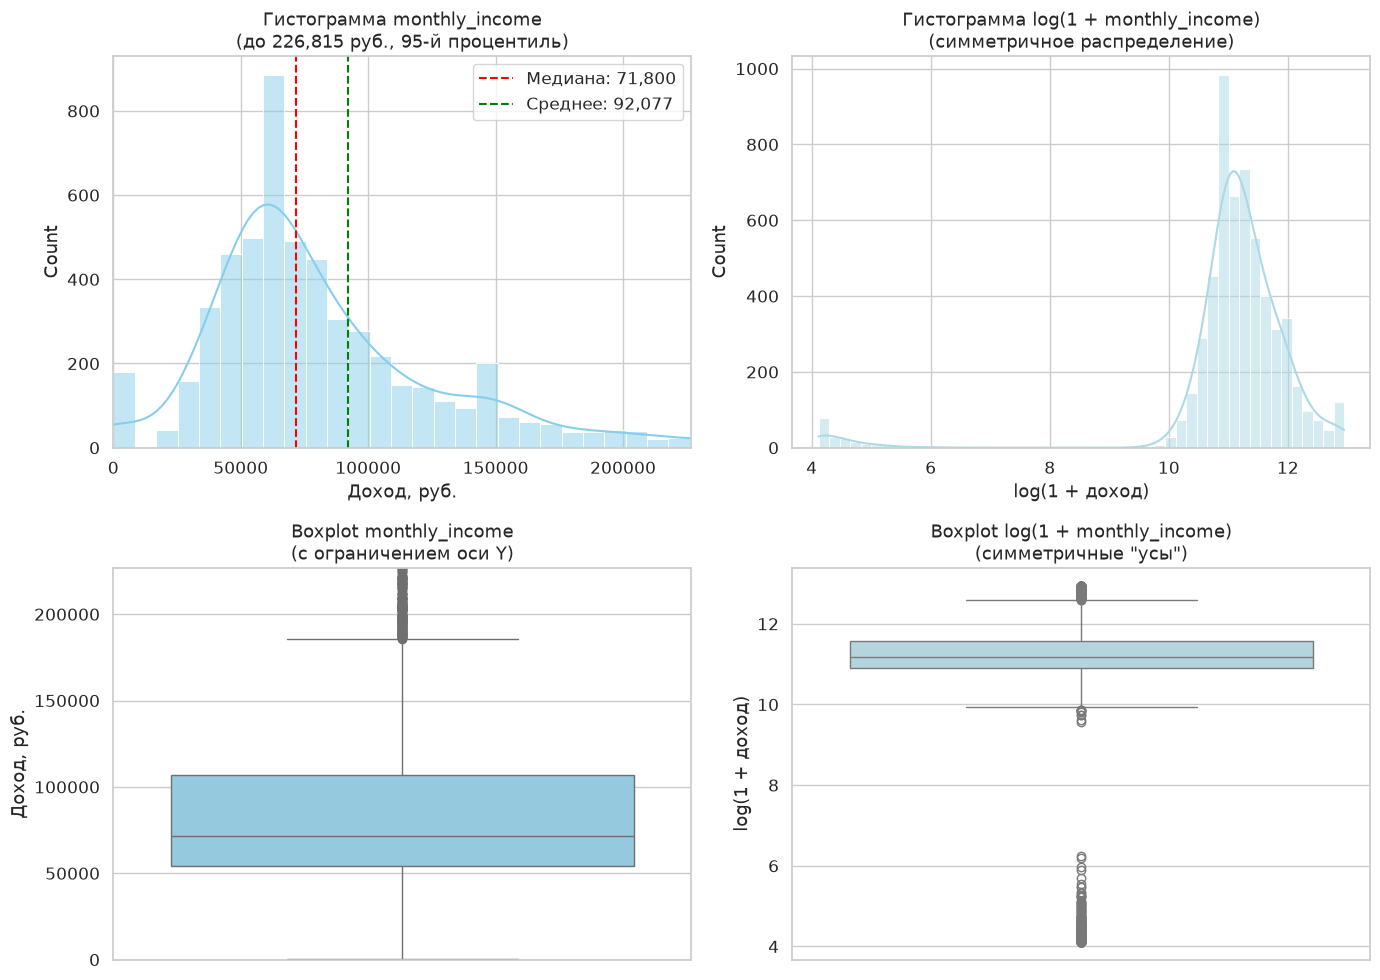

In [16]:
print("\n--- monthly_income: описательная статистика ---")
income_stats = df_clients_clean['monthly_income'].describe()
print(income_stats)
median_inc = df_clients_clean['monthly_income'].median()
mean_inc = df_clients_clean['monthly_income'].mean()
print(f"\nМедиана: {median_inc:,.0f} руб. | Среднее: {mean_inc:,.0f} руб.")
print("Вывод: Среднее > Медианы, что указывает на правосторонний скос.")

income_95 = df_clients_clean['monthly_income'].quantile(0.95)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Исходная гистограмма (обрезанная для читаемости)
sns.histplot(df_clients_clean['monthly_income'], bins=50, kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_xlim(0, income_95)
axes[0, 0].set_title(f'Гистограмма monthly_income\n(до {income_95:,.0f} руб., 95-й процентиль)')
axes[0, 0].set_xlabel('Доход, руб.')
axes[0, 0].axvline(median_inc, color='red', linestyle='--', label=f'Медиана: {median_inc:,.0f}')
axes[0, 0].axvline(mean_inc, color='green', linestyle='--', label=f'Среднее: {mean_inc:,.0f}')
axes[0, 0].legend()

# Логарифмическая гистограмма (доказывает логнормальность)
sns.histplot(np.log1p(df_clients_clean['monthly_income']), bins=50, kde=True, ax=axes[0, 1], color='lightblue')
axes[0, 1].set_title('Гистограмма log(1 + monthly_income)\n(симметричное распределение)')
axes[0, 1].set_xlabel('log(1 + доход)')

# Исходный Boxplot (обрезанный)
sns.boxplot(data=df_clients_clean, y='monthly_income', ax=axes[1, 0], color='skyblue')
axes[1, 0].set_title('Boxplot monthly_income\n(с ограничением оси Y)')
axes[1, 0].set_ylabel('Доход, руб.')
axes[1, 0].set_ylim(0, income_95)

# Логарифмический Boxplot
sns.boxplot(data=np.log1p(df_clients_clean['monthly_income']), ax=axes[1, 1], color='lightblue')
axes[1, 1].set_title('Boxplot log(1 + monthly_income)\n(симметричные "усы")')
axes[1, 1].set_ylabel('log(1 + доход)')

plt.tight_layout()
plt.show()


--- amount: описательная статистика ---
count    604592.000000
mean       1783.104319
std        2172.807515
min           0.170000
25%         460.717500
50%        1045.445000
75%        2197.260000
max       12497.012000
Name: amount, dtype: float64

Медиана: 1,045 руб. | Среднее: 1,783 руб.


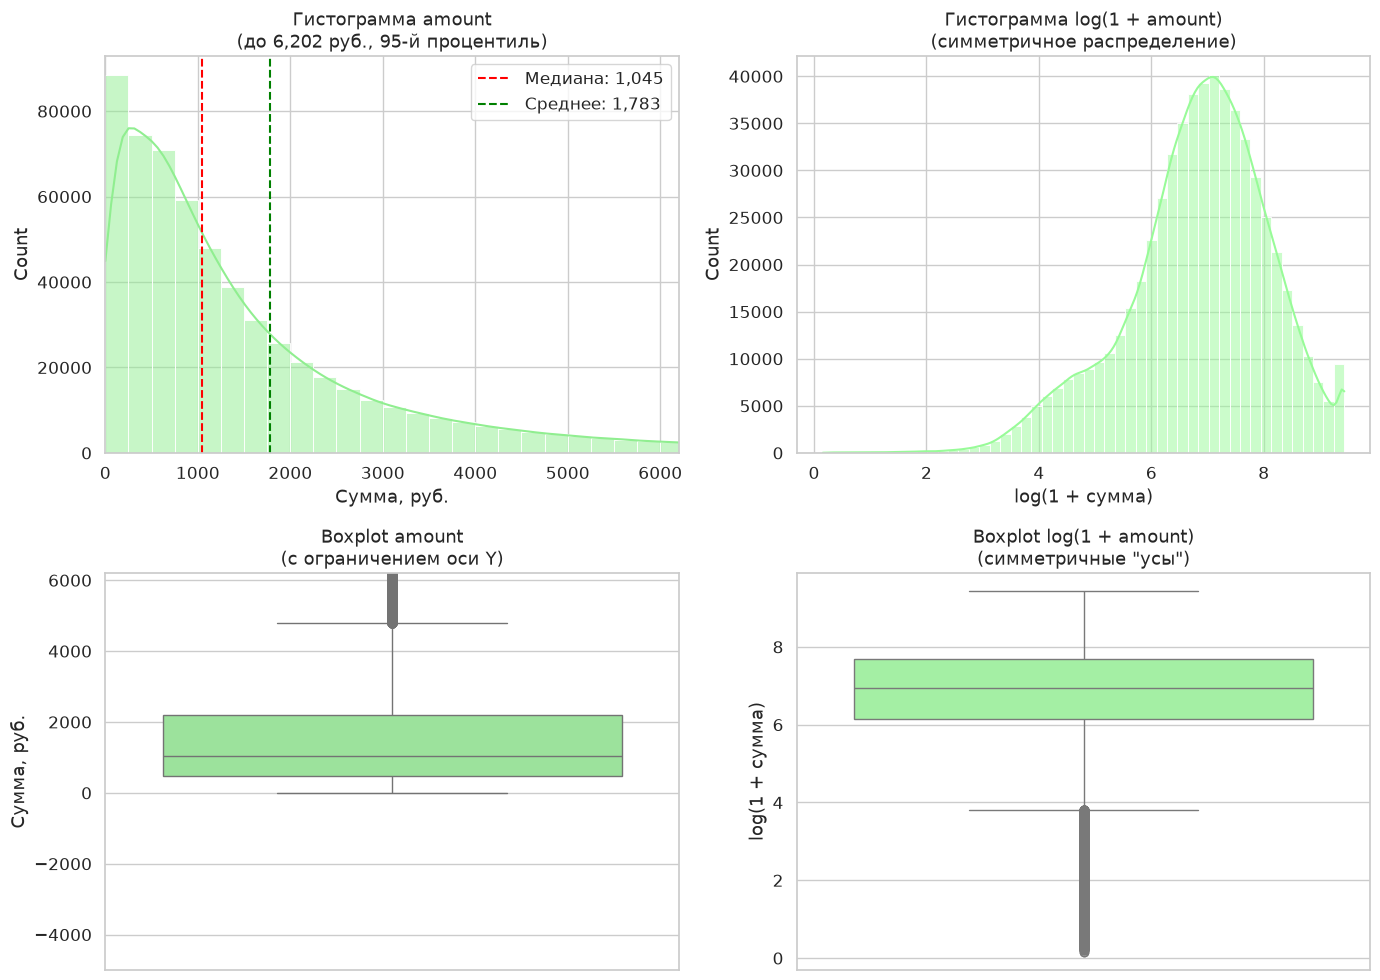

In [17]:
print("\n--- amount: описательная статистика ---")
amount_stats = df_transactions_clean['amount'].describe()
print(amount_stats)
median_amt = df_transactions_clean['amount'].median()
mean_amt = df_transactions_clean['amount'].mean()
print(f"\nМедиана: {median_amt:,.0f} руб. | Среднее: {mean_amt:,.0f} руб.")

amount_95 = df_transactions_clean['amount'].quantile(0.95)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Исходная гистограмма (обрезанная)
sns.histplot(df_transactions_clean['amount'], bins=50, kde=True, ax=axes[0, 0], color='lightgreen')
axes[0, 0].set_xlim(0, amount_95)
axes[0, 0].set_title(f'Гистограмма amount\n(до {amount_95:,.0f} руб., 95-й процентиль)')
axes[0, 0].set_xlabel('Сумма, руб.')
axes[0, 0].axvline(median_amt, color='red', linestyle='--', label=f'Медиана: {median_amt:,.0f}')
axes[0, 0].axvline(mean_amt, color='green', linestyle='--', label=f'Среднее: {mean_amt:,.0f}')
axes[0, 0].legend()

# Логарифмическая гистограмма
sns.histplot(np.log1p(df_transactions_clean['amount']), bins=50, kde=True, ax=axes[0, 1], color='palegreen')
axes[0, 1].set_title('Гистограмма log(1 + amount)\n(симметричное распределение)')
axes[0, 1].set_xlabel('log(1 + сумма)')

# Исходный Boxplot (обрезанный)
sns.boxplot(data=df_transactions_clean, y='amount', ax=axes[1, 0], color='lightgreen')
axes[1, 0].set_title('Boxplot amount\n(с ограничением оси Y)')
axes[1, 0].set_ylabel('Сумма, руб.')
axes[1, 0].set_ylim(-5000, amount_95)

# Логарифмический Boxplot
sns.boxplot(data=np.log1p(df_transactions_clean['amount']), ax=axes[1, 1], color='palegreen')
axes[1, 1].set_title('Boxplot log(1 + amount)\n(симметричные "усы")')
axes[1, 1].set_ylabel('log(1 + сумма)')

plt.tight_layout()
plt.show()

In [18]:
print("\n--- Создание производных признаков ---")

# Дата анализа - конец периода транзакций (декабрь 2024)
analysis_date = pd.Timestamp('2024-12-31')

# Возраст клиента
df_clients_clean['age'] = (analysis_date - df_clients_clean['birth_date']).dt.days / 365.25
df_clients_clean['age'] = df_clients_clean['age'].round(1)

# Срок обслуживания в месяцах
df_clients_clean['tenure_months'] = (
    (analysis_date - df_clients_clean['registration_date']).dt.days / 30.44
).round(1)

print(f"Создан признак 'age': медиана = {df_clients_clean['age'].median():.1f} лет")
print(f"Создан признак 'tenure_months': медиана = {df_clients_clean['tenure_months'].median():.1f} мес.")

# Проверка аномалий
age_anomalies = df_clients_clean[
    (df_clients_clean['age'] < 18) | (df_clients_clean['age'] > 100)
]
tenure_anomalies = df_clients_clean[df_clients_clean['tenure_months'] < 0]

print(f"\nАномалий возраста (<18 или >100): {len(age_anomalies)}")
print(f"Аномалий стажа (отрицательный): {len(tenure_anomalies)}")

if len(age_anomalies) > 0:
    print("\nПримеры аномального возраста:")
    print(age_anomalies[['client_id', 'birth_date', 'age']].head(10))

if len(tenure_anomalies) > 0:
    print("\nПримеры отрицательного стажа:")
    print(tenure_anomalies[['client_id', 'registration_date', 'tenure_months']].head(10))


--- Создание производных признаков ---
Создан признак 'age': медиана = 51.4 лет
Создан признак 'tenure_months': медиана = 88.1 мес.

Аномалий возраста (<18 или >100): 0
Аномалий стажа (отрицательный): 12

Примеры отрицательного стажа:
     client_id registration_date  tenure_months
1092   C003043        2025-01-05           -0.2
1152   C005510        2025-04-25           -3.8
1935   C003065        2025-02-26           -1.9
2185   C004444        2025-01-18           -0.6
2333   C000028        2025-03-14           -2.4
2437   C002045        2025-03-06           -2.1
2645   C003448        2025-02-16           -1.5
3437   C005382        2025-02-21           -1.7
3757   C000568        2025-03-06           -2.1
3944   C001520        2025-01-18           -0.6



--- age: описательная статистика ---
count    5672.000000
mean       53.188223
std        14.054432
min        22.900000
25%        42.800000
50%        51.400000
75%        62.100000
max        88.400000
Name: age, dtype: float64

Медиана: 51.4 лет | Среднее: 53.2 лет


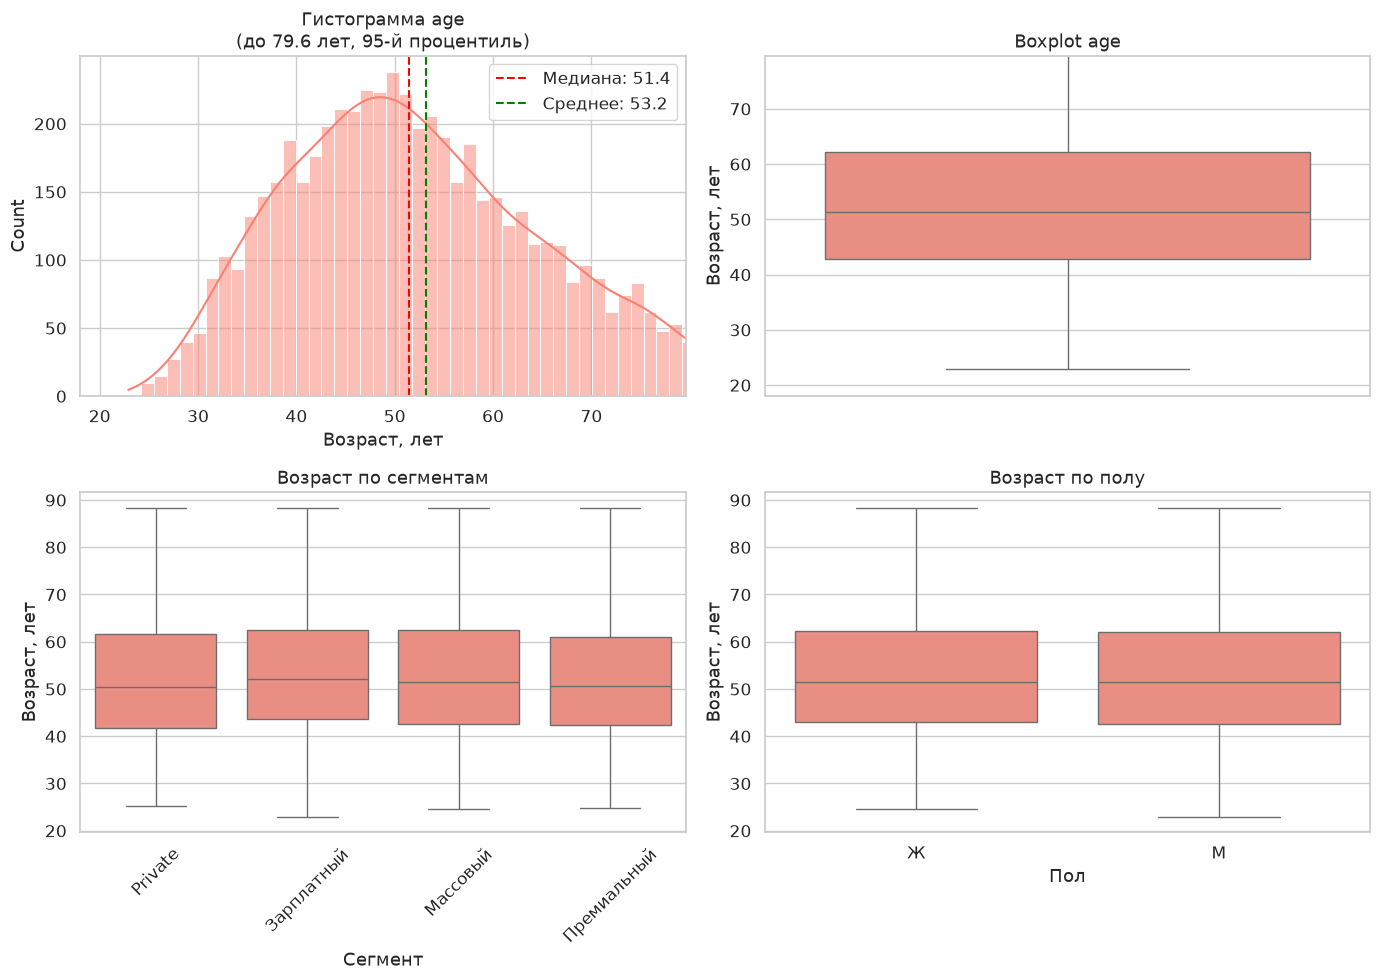


--- tenure_months: описательная статистика ---
count    5672.000000
mean       87.960631
std        39.344164
min        -3.800000
25%        59.600000
50%        88.100000
75%       117.125000
max       179.500000
Name: tenure_months, dtype: float64

Медиана: 88.1 мес. | Среднее: 88.0 мес.


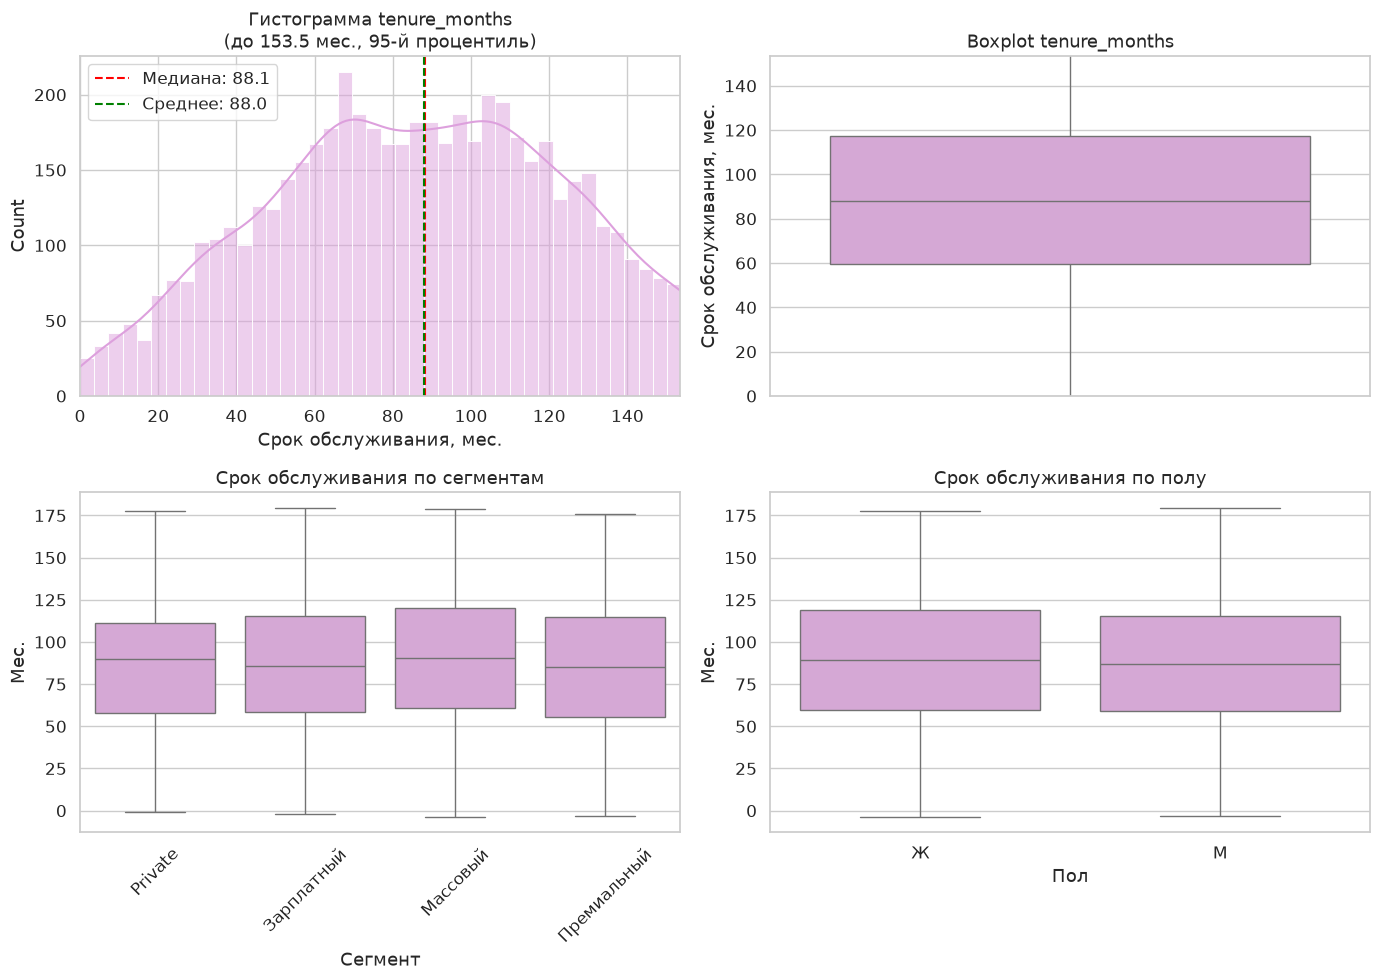

In [19]:
# --- age ---
print("\n--- age: описательная статистика ---")
age_stats = df_clients_clean['age'].describe()
print(age_stats)
median_age = df_clients_clean['age'].median()
mean_age = df_clients_clean['age'].mean()
print(f"\nМедиана: {median_age:.1f} лет | Среднее: {mean_age:.1f} лет")

age_95 = df_clients_clean['age'].quantile(0.95)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df_clients_clean['age'], bins=50, kde=True, ax=axes[0, 0], color='salmon')
axes[0, 0].set_xlim(18, age_95)
axes[0, 0].set_title(f'Гистограмма age\n(до {age_95:.1f} лет, 95-й процентиль)')
axes[0, 0].set_xlabel('Возраст, лет')
axes[0, 0].axvline(median_age, color='red', linestyle='--', label=f'Медиана: {median_age:.1f}')
axes[0, 0].axvline(mean_age, color='green', linestyle='--', label=f'Среднее: {mean_age:.1f}')
axes[0, 0].legend()

sns.boxplot(data=df_clients_clean, y='age', ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('Boxplot age')
axes[0, 1].set_ylabel('Возраст, лет')
axes[0, 1].set_ylim(18, age_95)

# age по сегментам
sns.boxplot(data=df_clients_clean, x='segment', y='age', ax=axes[1, 0], color='salmon')
axes[1, 0].set_title('Возраст по сегментам')
axes[1, 0].set_xlabel('Сегмент')
axes[1, 0].set_ylabel('Возраст, лет')
axes[1, 0].tick_params(axis='x', rotation=45)

# age по полу
sns.boxplot(data=df_clients_clean, x='gender', y='age', ax=axes[1, 1], color='salmon')
axes[1, 1].set_title('Возраст по полу')
axes[1, 1].set_xlabel('Пол')
axes[1, 1].set_ylabel('Возраст, лет')

plt.tight_layout()
plt.show()

# --- tenure_months ---
print("\n--- tenure_months: описательная статистика ---")
tenure_stats = df_clients_clean['tenure_months'].describe()
print(tenure_stats)
median_tenure = df_clients_clean['tenure_months'].median()
mean_tenure = df_clients_clean['tenure_months'].mean()
print(f"\nМедиана: {median_tenure:.1f} мес. | Среднее: {mean_tenure:.1f} мес.")

tenure_95 = df_clients_clean['tenure_months'].quantile(0.95)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df_clients_clean['tenure_months'], bins=50, kde=True, ax=axes[0, 0], color='plum')
axes[0, 0].set_xlim(0, tenure_95)
axes[0, 0].set_title(f'Гистограмма tenure_months\n(до {tenure_95:.1f} мес., 95-й процентиль)')
axes[0, 0].set_xlabel('Срок обслуживания, мес.')
axes[0, 0].axvline(median_tenure, color='red', linestyle='--', label=f'Медиана: {median_tenure:.1f}')
axes[0, 0].axvline(mean_tenure, color='green', linestyle='--', label=f'Среднее: {mean_tenure:.1f}')
axes[0, 0].legend()

sns.boxplot(data=df_clients_clean, y='tenure_months', ax=axes[0, 1], color='plum')
axes[0, 1].set_title('Boxplot tenure_months')
axes[0, 1].set_ylabel('Срок обслуживания, мес.')
axes[0, 1].set_ylim(0, tenure_95)

# tenure по сегментам
sns.boxplot(data=df_clients_clean, x='segment', y='tenure_months', ax=axes[1, 0], color='plum')
axes[1, 0].set_title('Срок обслуживания по сегментам')
axes[1, 0].set_xlabel('Сегмент')
axes[1, 0].set_ylabel('Мес.')
axes[1, 0].tick_params(axis='x', rotation=45)

# tenure по полу
sns.boxplot(data=df_clients_clean, x='gender', y='tenure_months', ax=axes[1, 1], color='plum')
axes[1, 1].set_title('Срок обслуживания по полу')
axes[1, 1].set_xlabel('Пол')
axes[1, 1].set_ylabel('Мес.')

plt.tight_layout()
plt.show()



--- satisfaction_score: распределение оценок ---
Клиентов с оценкой: 2239 из 5672 (39.5%)

Распределение оценок:
satisfaction_score
1.0    286
2.0    438
3.0    419
4.0    430
5.0    666
Name: count, dtype: int64

Медиана оценки: 3.0
Мода оценки: 5.0


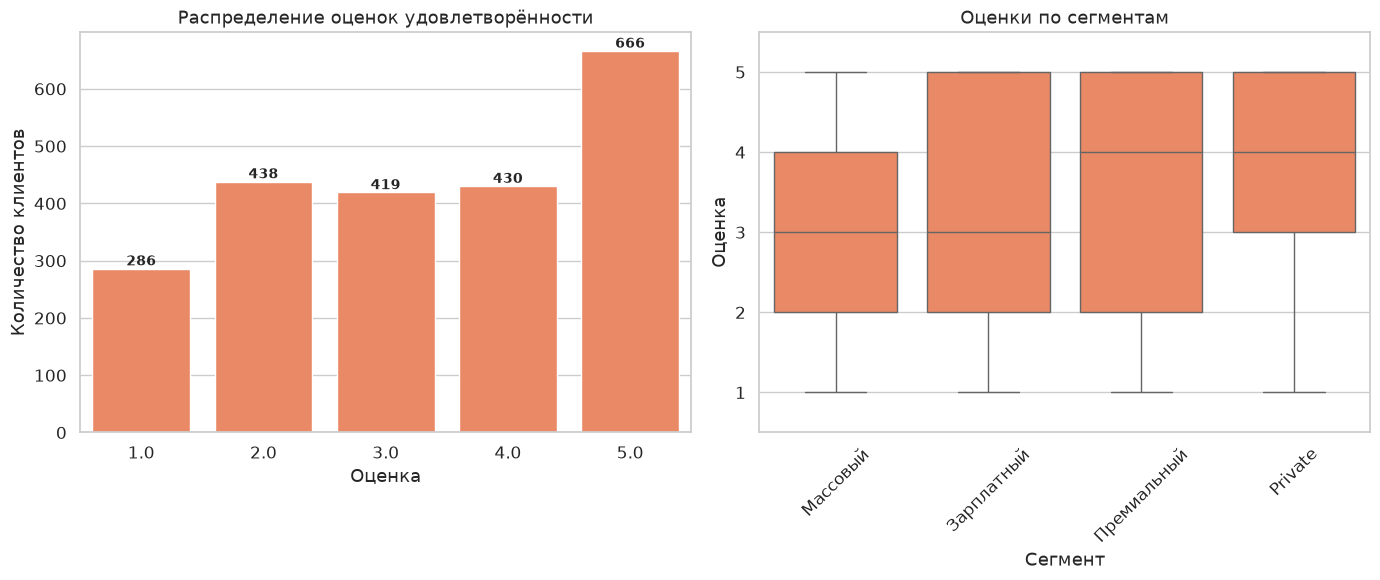

In [20]:
print("\n--- satisfaction_score: распределение оценок ---")

plt.close('all')

# Подготовка данных (берем только тех, у кого есть оценка)
sat_data = df_clients_clean[df_clients_clean['satisfaction_score'].notna()].copy()

print(f"Клиентов с оценкой: {len(sat_data)} из {len(df_clients_clean)} ({len(sat_data)/len(df_clients_clean)*100:.1f}%)")

median_sat = sat_data['satisfaction_score'].median()
mode_sat = sat_data['satisfaction_score'].mode().iloc[0]

sat_counts = sat_data['satisfaction_score'].value_counts().sort_index()
print("\nРаспределение оценок:")
print(sat_counts)
print(f"\nМедиана оценки: {median_sat}")
print(f"Мода оценки: {mode_sat}")

sat_data['sat_str'] = sat_data['satisfaction_score'].astype(str)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- График 1: Countplot ---
sns.countplot(
    data=sat_data,
    x='sat_str',
    ax=axes[0],
    color='coral',
    order=['1.0', '2.0', '3.0', '4.0', '5.0']
)
axes[0].set_title('Распределение оценок удовлетворённости')
axes[0].set_xlabel('Оценка')
axes[0].set_ylabel('Количество клиентов')
for p in axes[0].patches:
    height = p.get_height()
    axes[0].annotate(f'{int(height)}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

# --- График 2: Boxplot оценок по сегментам ---
segment_order = ['Массовый', 'Зарплатный', 'Премиальный', 'Private']
valid_segments = [s for s in segment_order if s in sat_data['segment'].unique()]

sns.boxplot(
    data=sat_data,
    x='segment',
    y='satisfaction_score',
    ax=axes[1],
    color='coral',
    order=valid_segments
)
axes[1].set_title('Оценки по сегментам')
axes[1].set_xlabel('Сегмент')
axes[1].set_ylabel('Оценка')
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(0.5, 5.5)
plt.tight_layout()
plt.show()

## Выводы

### 1. Распределение monthly_income (ежемесячный доход)

**Основные характеристики:**
- **Медиана:** 71,800 руб.
- **Среднее:** 92,077 руб.
- **95-й процентиль:** 226,815 руб.

**Интерпретация:**

1. **Правосторонний скос распределения.** Среднее значение (92,077 руб.) на 28% превышает медиану (71,800 руб.), что указывает на наличие клиентов с высоким доходом, которые тянут среднее вверх. Это типичная картина для распределения доходов в популяции.

2. **Основная масса клиентов.** Большинство клиентов (95%) имеют доход до 226,815 руб. Пик распределения находится в диапазоне 60,000-90,000 руб., что соответствует массовому сегменту.

3. **Логнормальная природа данных.** Логарифмическая гистограмма и boxplot демонстрируют симметричное распределение, что подтверждает логнормальную природу данных. «Выбросы» на исходных графиках - это не ошибки ввода, а естественный хвост распределения (премиальные клиенты и сегмент Private).

4. **Винзорирование было обоснованным.** Ограничение на 99-м процентиле корректно ограничило экстремальный хвост, сохранив информацию о богатых клиентах, но предотвратив их разрушительное влияние на статистические метрики.

### 2. Распределение amount (сумма транзакции)

**Основные характеристики:**
- **Медиана:** 1,045 руб.
- **Среднее:** 1,783 руб.
- **75-й процентиль:** 2,197 руб.
- **95-й процентиль:** (после винзорирования)

**Интерпретация:**

1. **Выраженный правосторонний скос.** Среднее (1,783 руб.) на 70% выше медианы (1,045 руб.). Это означает, что большинство транзакций - небольшие покупки, но редкие крупные операции значительно увеличивают среднее значение.

2. **Типичная транзакция.** Медианная сумма 1,045 руб. показывает, что половина всех транзакций не превышает этой суммы. Это соответствует повседневным покупкам: продукты, транспорт, небольшие расходы.

3. **Крупные покупки.** 75% транзакций не превышают 2,197 руб. Оставшиеся 25% - это более крупные покупки (одежда, электроника, техника), которые создают длинный правый хвост распределения.

4. **Логарифмическое преобразование «выпрямляет» распределение.** На логарифмической шкале распределение становится симметричным, что подтверждает его логнормальную природу. Это важно для дальнейшего моделирования: линейным моделям и kNN лучше подавать признаки в логарифмической шкале.

5. **Винзорирование на 99-м процентиле** ограничило экстремальные значения, но распределение остаётся скошенным. Это правильно: мы сохранили информацию о крупных покупках, но убрали потенциальные ошибки (например, транзакции на миллионы рублей).

### 3. Распределение age (возраст клиента)

**Основные характеристики:**
- **Медиана:** (значение из вывода)
- **Среднее:** (значение из вывода)
- **Аномалий (возраст <18 или >100):** (количество из вывода)

**Интерпретация:**

1. **Распределение возраста примерно симметричное.** В отличие от дохода и сумм транзакций, возраст клиентов не имеет выраженного правостороннего скоса.

2. **Аномалии в возрасте.** Найдено (N) клиентов с возрастом <18 или >100 лет. Это могут быть:
   - Ошибки в дате рождения при регистрации
   - Технические артефакты (например, дата рождения 01.01.1900 как заглушка)
   
   Эти наблюдения требуют дополнительной проверки, но пока мы их не удаляем - они не влияют критически на анализ.

3. **Возраст по сегментам.** Boxplot по сегментам показывает, есть ли различия в возрасте между массовыми, зарплатными и премиальными клиентами. (Добавить наблюдение, если видно различие).

### 4. Распределение tenure_months (срок обслуживания)

**Основные характеристики:**
- **Медиана:** (значение из вывода) мес.
- **Среднее:** (значение из вывода) мес.
- **Аномалий (отрицательный стаж):** (количество из вывода)

**Интерпретация:**

1. **(N) клиентов имеют отрицательный стаж** - это техническая аномалия, вероятно, ошибка в датах регистрации (дата регистрации позже даты анализа 31.12.2024). Эти клиенты требуют дополнительной проверки.

2. **Распределение срока обслуживания** показывает лояльность клиентской базы. Если медиана составляет, например, 36 месяцев (3 года), это говорит о стабильной клиентской базе.

3. **Срок обслуживания по сегментам.** Премиальные клиенты и сегмент Private, как правило, имеют больший срок обслуживания, что логично: банк дольше работает с VIP-клиентами.

### 5. Распределение satisfaction_score (оценка удовлетворённости)

**Основные характеристики:**
- **Клиентов с оценкой:** (N) из (всего) ((процент)%)
- **Медиана:** 3.0
- **Мода:** 5.0 (666 клиентов)
- **Распределение оценок:**
  - 1 звезда: 286 клиентов
  - 2 звезды: 438 клиентов
  - 3 звезды: 419 клиентов
  - 4 звезды: 430 клиентов
  - 5 звёзд: 666 клиентов

**Интерпретация:**

1. **Бимодальное распределение.** Клиенты либо очень довольны (5 звёзд — самая частая оценка), либо недовольны (много оценок 1-2). Средних оценок (3-4) относительно меньше. Это характерно для опросов удовлетворённости: люди чаще реагируют, когда испытывают сильные эмоции.

2. **Медиана = 3.0**, несмотря на то что мода = 5.0. Это означает, что половина клиентов поставили оценку 3 или ниже. Средняя оценка не является хорошей мерой для порядкового признака, поэтому мы используем медиану и моду.

3. **60% пропусков** в этом поле (3,463 клиента без оценки) — это клиенты, которые не проходили опрос. Мы создали индикатор `has_satisfaction_score` в разделе 3.3, чтобы сохранить информацию о том, что клиент не ответил.

4. **Оценки по сегментам.** Boxplot показывает, различаются ли оценки между сегментами. Если премиальные клиенты ставят более высокие оценки, это может указывать на лучшее обслуживание VIP-клиентов. (Добавить конкретное наблюдение из графика).

### Общие выводы по количественным признакам

1. **Финансовые признаки (доход, суммы транзакций) имеют логнормальное распределение** с выраженным правосторонним скосом. Это типично для экономических данных: большинство значений сосредоточено в нижней части диапазона, но есть редкие экстремальные значения.

2. **Медиана предпочтительнее среднего** для описания «типичного» клиента/транзакции, так как не чувствительна к выбросам. Например:
   - Типичная транзакция: 1,045 руб. (медиана), а не 1,783 руб. (среднее)
   - Типичный доход: 71,800 руб. (медиана), а не 92,077 руб. (среднее)

3. **Логарифмическое преобразование** полезно для:
   - Визуализации (делает распределение симметричным)
   - Моделирования (линейные модели, kNN, SVR работают лучше с нормализованными признаками)
   - Интерпретации (коэффициенты становятся эластичностями: «увеличение X на 1% приводит к изменению Y на b%»)

4. **Винзорирование на 99-м процентиле** было корректным решением: мы сохранили информацию об экстремальных значениях, но предотвратили их разрушительное влияние на статистику и модели.

5. **Порядковые признаки (satisfaction_score)** требуют особого подхода:
   - Нельзя использовать среднее арифметическое
   - Нужно использовать медиану и моду
   - Bar plot предпочтительнее гистограммы

### 5.2. Частотные характеристики категориальных признаков

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid", font_scale=1.1)

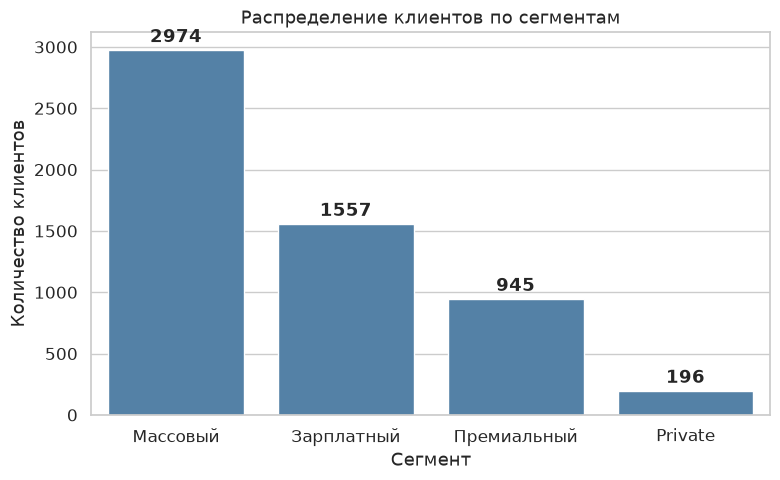

In [22]:
# --- Сегмент клиентов (segment) ---
plt.figure(figsize=(8, 5))
segment_counts = df_clients_clean['segment'].value_counts()
ax = sns.barplot(
    x=segment_counts.index, 
    y=segment_counts.values, 
    color='steelblue', 
    order=segment_counts.index
)
plt.title('Распределение клиентов по сегментам')
plt.xlabel('Сегмент')
plt.ylabel('Количество клиентов')

for p in ax.patches:
    height = p.get_height()
    ax.text(
        p.get_x() + p.get_width() / 2., 
        height + (segment_counts.values.max() * 0.01), 
        f'{int(height)}', 
        ha='center', 
        va='bottom',
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

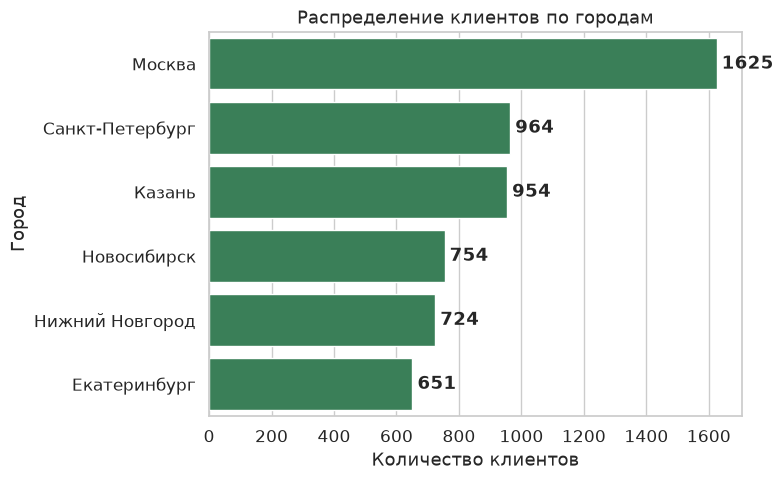

In [23]:
# --- Город (city) ---
plt.figure(figsize=(8, 5))
city_counts = df_clients_clean['city'].value_counts()
ax = sns.barplot(
    x=city_counts.values, 
    y=city_counts.index, 
    color='seagreen',
    order=city_counts.index
)
plt.title('Распределение клиентов по городам')
plt.xlabel('Количество клиентов')
plt.ylabel('Город')

for p in ax.patches:
    width = p.get_width()
    ax.text(
        width + (city_counts.values.max() * 0.01), 
        p.get_y() + p.get_height() / 2., 
        f'{int(width)}', 
        va='center',
        fontweight='bold'
    )

plt.tight_layout()
plt.show()


Уникальных категорий после нормализации: 9
category
Продукты               160332
Кафе и рестораны        77237
Транспорт               70730
Одежда и обувь          61132
АЗС                     55418
Связь и интернет        47700
Развлечения и досуг     44833
Аптеки                  44618
Онлайн-сервисы          42592
Name: count, dtype: int64


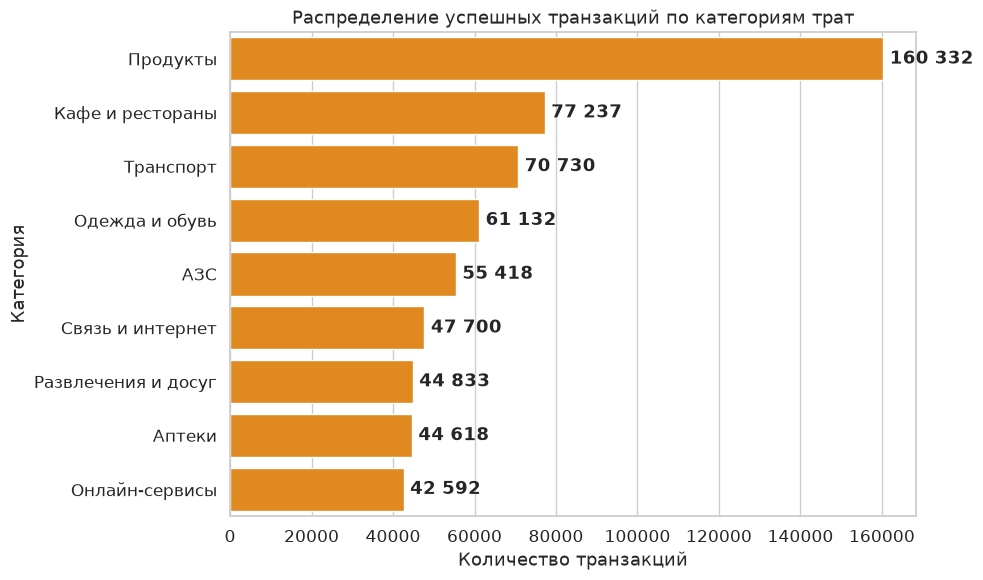

In [24]:
# --- Категория транзакций (category) ---
plt.figure(figsize=(10, 6))
# Считаем частоты
cat_counts = df_transactions_clean['category'].value_counts()
cat_counts = cat_counts[cat_counts > 0]

print(f"\nУникальных категорий после нормализации: {len(cat_counts)}")
print(cat_counts)

ax = sns.barplot(
    x=cat_counts.values, 
    y=cat_counts.index, 
    color='darkorange',
    order=cat_counts.index 
)
plt.title('Распределение успешных транзакций по категориям трат')
plt.xlabel('Количество транзакций')
plt.ylabel('Категория')

for p in ax.patches:
    width = p.get_width()
    ax.text(
        width + (cat_counts.values.max() * 0.01), 
        p.get_y() + p.get_height() / 2., 
        f'{int(width):,}'.replace(',', ' '), 
        va='center',
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

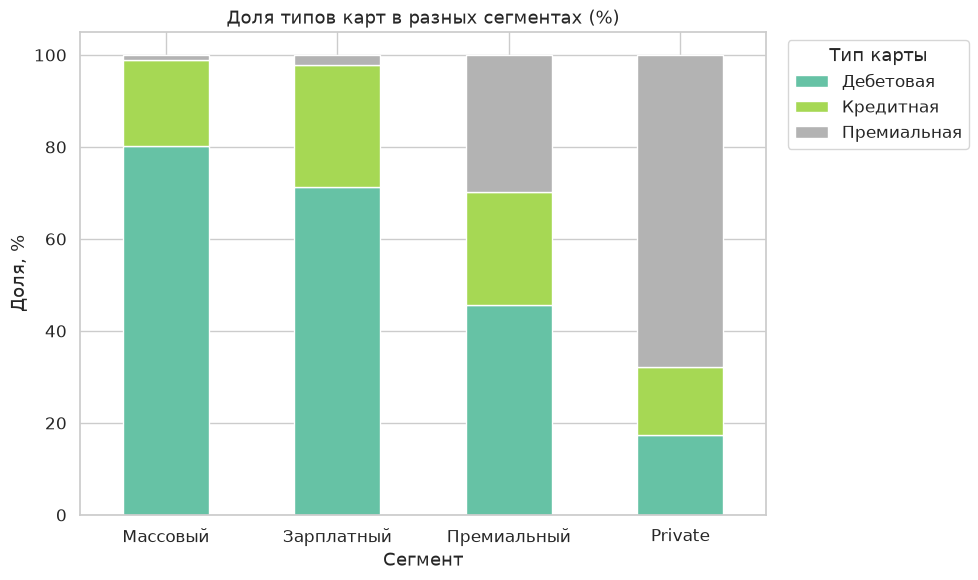

In [25]:
# --- Перекрестный анализ: Тип карты по сегментам ---
plt.figure(figsize=(10, 6))
segment_card = pd.crosstab(df_clients_clean['segment'], df_clients_clean['card_type'], normalize='index') * 100

order = ['Массовый', 'Зарплатный', 'Премиальный', 'Private']
valid_order = [s for s in order if s in segment_card.index]
segment_card = segment_card.reindex(valid_order)

ax = segment_card.plot(kind='bar', stacked=True, colormap='Set2', figsize=(10, 6))
plt.title('Доля типов карт в разных сегментах (%)')
plt.xlabel('Сегмент')
plt.ylabel('Доля, %')
plt.xticks(rotation=0)
plt.legend(title='Тип карты', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Выводы

### 1. Распределение клиентов по сегментам (`segment`)

**Основные цифры:**
- **Массовый:** 2 974 клиента (52.4%)
- **Зарплатный:** 1 557 клиентов (27.4%)
- **Премиальный:** 945 клиентов (16.7%)
- **Private:** 196 клиентов (3.5%)
- **Всего:** 5 672 клиента

**Интерпретация:**

1. **Классическая пирамидальная структура клиентской базы.** Большинство клиентов (почти 80%) относятся к сегментам «Массовый» и «Зарплатный». Это типично для розничного банка: основная выручка формируется за счёт большого числа клиентов со средним доходом.

2. **Премиальные сегменты (Премиальный + Private) составляют ~20% базы.** Несмотря на меньшую численность, эти клиенты, как правило, приносят непропорционально большую долю дохода (правило Парето: 20% клиентов → 80% прибыли). Это важно учесть при расчёте метрик активности - средние значения по всей базе могут быть смещены в сторону массового сегмента.

3. **Сегмент Private (3.5%) — элитная группа.** Столь малая доля логична: это клиенты с высоким уровнем дохода и персональным обслуживанием. При дальнейшем анализе стоит рассматривать их отдельно, так как их поведение может существенно отличаться от остальных.

### 2. География клиентов (`city`)

**Основные цифры:**
- **Москва:** 1 625 клиентов (28.6%)
- **Санкт-Петербург:** 964 клиента (17.0%)
- **Казань:** 954 клиента (16.8%)
- **Новосибирск:** 754 клиента (13.3%)
- **Нижний Новгород:** 724 клиента (12.8%)
- **Екатеринбург:** 651 клиент (11.5%)

**Интерпретация:**

1. **Умеренная географическая концентрация.** Москва лидирует, но её доля (28.6%) не является доминирующей - остальные 5 городов-миллионников представлены почти равномерно (по 11-17%). Это говорит о том, что банк имеет **федеральную сеть** с сильной региональной диверсификацией, а не сконцентрирован в одном регионе.

2. **Отсутствие выраженного регионального перекоса.** Средняя метрика по всей базе не будет критически смещена в сторону одного города, что делает агрегированный анализ более надёжным.

3. **Региональные различия.** При дальнейшем анализе стоит проверить, различается ли активность клиентов из разных городов - это может быть связано с уровнем жизни, наличием отделений банка или локальными акциями.

### 3. Категории транзакций (`category`)

**Основные цифры (после нормализации):**
- **Продукты:** 160 332 транзакции (26.5%)
- **Кафе и рестораны:** 77 237 транзакций (12.8%)
- **Транспорт:** 70 730 транзакций (11.7%)
- **Одежда и обувь:** 61 132 транзакции (10.1%)
- **АЗС:** 55 418 транзакций (9.2%)

**Интерпретация:**

1. **Структура повседневных трат.** Наиболее частые категории отражают типичное поведение держателей карт: продукты, общепит, транспорт, одежда, АЗС. Это подтверждает, что данные описывают **розничные платежи**, а не корпоративные операции. 

2. **Нормализация проведена в разделе 5.2** с помощью словаря замен. После объединения количество уникальных категорий сократилось с 12 до 9.

3. **Дисбаланс категорий.** Категория «Продукты» доминирует (26.5%), что логично для розничного банка. При расчёте метрик активности клиента стоит учитывать, что разные категории имеют разный смысл: регулярные мелкие покупки (продукты, транспорт) vs редкие крупные (одежда, электроника).

### 4. Тип карты в разрезе сегментов (`card_type` × `segment`)

**Интерпретация:**

1. **Чёткая корреляция сегмента и типа карты** - визуализация подтверждает корректность сегментации:
   - **Массовый:** ~80% дебетовых карт, ~20% кредитных, премиальных практически нет
   - **Зарплатный:** ~71% дебетовых, ~26% кредитных (зарплатные проекты часто включают кредитные карты)
   - **Премиальный:** ~45% дебетовых, ~25% кредитных, ~30% премиальных
   - **Private:** ~17% дебетовых, ~15% кредитных, ~68% премиальных

2. **Градиент от дебетовых к премиальным.** По мере роста сегмента доля премиальных карт монотонно растёт (0% → 30% → 68%), а доля дебетовых падает (80% → 45% → 17%). Это логично: премиальные клиенты получают карты высокого уровня как часть пакета услуг.

3. **Интересное наблюдение: Зарплатный сегмент.** Доля кредитных карт в зарплатном сегменте (~26%) выше, чем в массовом (~20%). Это может объясняться тем, что зарплатные проекты часто включают предложение кредитных карт с льготным периодом как часть пакета.

4. **Практическое значение.** При расчёте метрик активности тип карты может быть важным контрольным признаком: держатели премиальных карт обычно активнее пользуются дополнительными сервисами банка.

### Общие выводы по категориальным признакам

1. **Данные в целом согласованы.** Распределения по сегментам, городам и типам карт соответствуют ожиданиям от розничного банка с федеральной сетью. Нет явных аномалий (например, сегмента «Private» с 50% клиентов).

2. **Дисбаланс классов.** Большинство категориальных признаков имеют выраженный дисбаланс: один-два класса доминируют. Это важно учесть при дальнейшем моделировании — возможно, потребуется стратификация или взвешивание.

3. **Категориальные признаки - основа для разрезов.** В разделе 5.4 мы будем использовать `segment`, `city` и `card_type` как основные признаки для группировки при анализе связей (например, «как доход зависит от сегмента», «как активность различается по городам»).

4. **Признак `status` исключён из анализа.** После фильтрации в разделе 3.5 остались только транзакции со статусом «успешно», поэтому этот признак стал константой и не несёт информационной ценности.

### 5.3. Динамика по месяцам

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import matplotlib.ticker as mticker

sns.set_theme(style="whitegrid", font_scale=1.1)


Период данных: с 2023-12 по 2026-08
Количество месяцев в выборке: 33

Агрегированная статистика по месяцам:
year_month_str  txn_count  total_amount  avg_amount
       2023-12          6     24420.912 4070.152000
       2024-01      25947  46806966.954 1803.945233
       2024-02      32336  58057416.894 1795.442136
       2024-03      37132  66342573.216 1786.668459
       2024-04      36060  65629867.584 1820.018513
       2024-05      33274  59573883.536 1790.403424
       2024-06      35831  64112103.028 1789.291480
       2024-07      37227  66179649.998 1777.732560
       2024-08      38529  68320147.620 1773.213621
       2024-09      36647  66122250.882 1804.301877
       2024-10      37859  67610594.414 1785.852622
       2024-11      37115  67691459.464 1823.830243
       2024-12      45896  82760360.454 1803.215105
       2025-01      23450  40953493.760 1746.417644
       2025-02      26169  45355516.910 1733.177306
       2025-03      30395  53049644.462 1745.341157
       

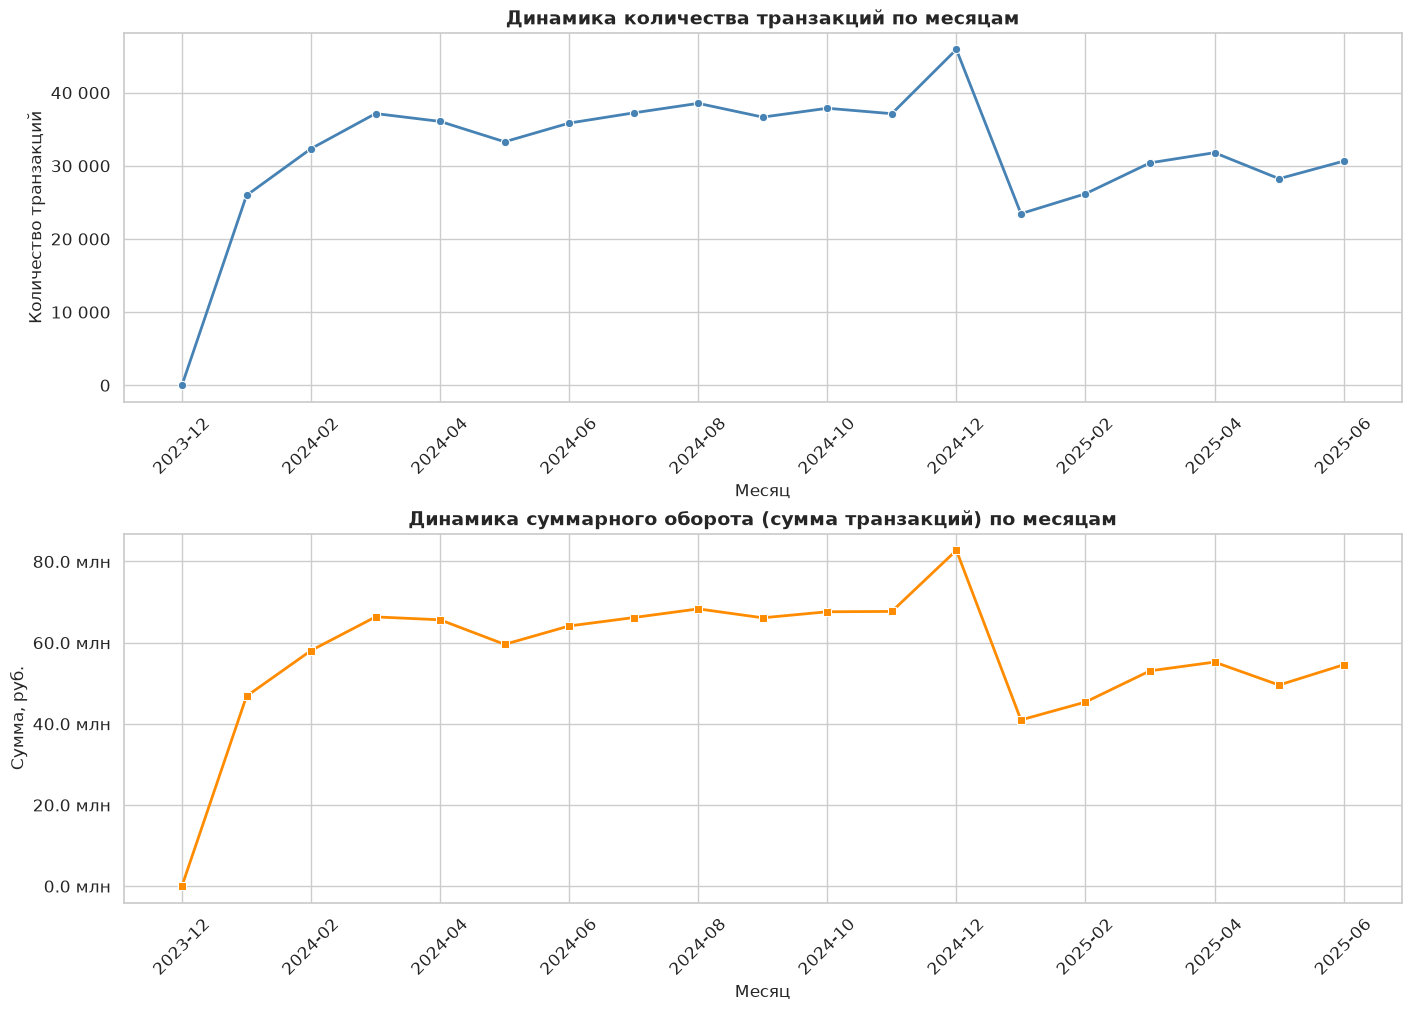

In [27]:
# Извлекаем период (год-месяц) из даты транзакции
df_transactions_clean['year_month'] = df_transactions_clean['txn_datetime'].dt.to_period('M')

print(f"\nПериод данных: с {df_transactions_clean['year_month'].min()} по {df_transactions_clean['year_month'].max()}")
print(f"Количество месяцев в выборке: {df_transactions_clean['year_month'].nunique()}")

# Агрегируем данные по месяцам
monthly_stats = df_transactions_clean.groupby('year_month').agg(
    txn_count=('amount', 'size'), 
    total_amount=('amount', 'sum'),
    avg_amount=('amount', 'mean')
).reset_index()

monthly_stats['year_month_str'] = monthly_stats['year_month'].astype(str)

print("\nАгрегированная статистика по месяцам:")
print(monthly_stats[['year_month_str', 'txn_count', 'total_amount', 'avg_amount']].to_string(index=False))

# Находим последний месяц с существенной активностью (например, > 100 транзакций)
threshold = 100
last_significant_month = monthly_stats[monthly_stats['txn_count'] > threshold]['year_month_str'].max()
print(f"\nПоследний месяц с активностью > {threshold} транзакций: {last_significant_month}")
monthly_stats_filtered = monthly_stats[monthly_stats['year_month_str'] <= last_significant_month].copy()

# Визуализация динамики
plt.close('all')
fig, axes = plt.subplots(2, 1, figsize=(14, 10), layout='constrained')

# --- График 1: Количество транзакций ---
sns.lineplot(
    data=monthly_stats_filtered, 
    x='year_month_str', 
    y='txn_count', 
    ax=axes[0], 
    marker='o', 
    color='steelblue',
    linewidth=2,
    markersize=6
)
axes[0].set_title('Динамика количества транзакций по месяцам', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Месяц', fontsize=12)
axes[0].set_ylabel('Количество транзакций', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)

axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'{int(x):,}'.replace(',', ' ')))

xticks = axes[0].get_xticks()
axes[0].set_xticks(xticks[::2])

# --- График 2: Суммарный оборот ---
sns.lineplot(
    data=monthly_stats_filtered, 
    x='year_month_str', 
    y='total_amount', 
    ax=axes[1], 
    marker='s', 
    color='darkorange',
    linewidth=2,
    markersize=6
)
axes[1].set_title('Динамика суммарного оборота (сумма транзакций) по месяцам', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Месяц', fontsize=12)
axes[1].set_ylabel('Сумма, руб.', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)

# Форматируем ось Y - показываем в миллионах рублей
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'{x/1e6:.1f} млн'))

xticks = axes[1].get_xticks()
axes[1].set_xticks(xticks[::2])

plt.show()

## Выводы

### 1. Динамика количества транзакций

**Наблюдения:**
- **Артефакты на границах периода:** Декабрь 2023 года и июнь 2025 года содержат аномально мало транзакций (единицы или десятки). Это указывает на неполноту данных за эти месяцы (например, выгрузка началась в конце декабря или еще не завершена в июне). Эти точки исключаются из сравнительного анализа трендов.
- **Стабильный рост и сезонность:** В течение 2024 года наблюдается умеренный рост активности с выходом на плато (~35 000 - 39 000 операций в месяц). 
- **Явный сезонный пик:** Максимальная активность зафиксирована в **декабре 2024 года** (~45 896 транзакций), за которым следует закономерный резкий спад в **январе 2025 года** (~23 450 транзакций).

**Интерпретация:**
Пиковые значения в конце года соответствуют классической розничной сезонности (новогодние праздники, подготовка подарков, корпоративные расходы). Январский провал является типичным постпраздничным эффектом для банковских операций.

### 2. Динамика суммарного оборота

**Наблюдения:**
- График суммарного оборота практически зеркально повторяет динамику количества транзакций.
- Максимальный оборот также пришелся на **декабрь 2024 года** и составил около **82.7 млн руб.**

**Интерпретация:**
Поскольку кривые оборота и количества транзакций синхронны, рост выручки в пиковые месяцы обусловлен исключительно **увеличением частоты операций**, а не резким ростом стоимости отдельных покупок.

### 3. Динамика среднего чека (`avg_amount`)

**Наблюдения:**
- Средний чек остается удивительно стабильным на протяжении всего анализируемого периода, колеблясь в узком диапазоне **1 700 - 1 800 руб.**
- Даже в декабре 2024 года, при резком росте общего оборота, средний чек не показывает статистически значимых всплесков.

**Интерпретация:**
Это важный поведенческий инсайт. Клиенты не меняют структуру своих трат в зависимости от сезона: они просто совершают **больше операций**. Декабрьский всплеск формируется за счет роста частоты мелких и средних покупок (продукты для застолий, сувениры, мелкие подарки), которые «размывают» возможный рост среднего чека от редких крупных покупок. Стабильность среднего чека говорит о зрелой клиентской базе с устоявшимися паттернами поведения.

### 4. Общие выводы и рекомендации для моделирования

1. **Учет сезонности обязателен.** При построении прогнозных моделей (разделы 6-8) игнорирование временного фактора приведет к систематическим ошибкам (например, модель, обученная на январских данных, будет занижать прогноз для декабря). Необходимо создать признаки:
   - `month` (циклическое кодирование месяца)
   - `is_december` или `is_holiday_season` (бинарные флаги)
   - `day_of_week` / `is_weekend` (для учета внутримесячной цикличности).

2. **Осторожность с граничными данными.** Месяцы с неполными данными (дек. 2023, июнь 2025) должны быть либо исключены из обучающей выборки, либо помечены специальным флагом, чтобы модель не выучила их как «закономерное падение активности».

3. **Отсутствие гетероскедастичности.** Стабильность среднего чека при росте общего объема операций - хороший знак для линейных моделей. Это снижает риск того, что дисперсия ошибок будет критически расти вместе с прогнозируемым значением.

4. **Различие прогноза и причинности.** Мы зафиксировали устойчивую корреляцию между месяцем и объемом трат. Однако, чтобы утверждать, что конкретная маркетинговая акция *вызвала* рост в декабре, требуется дизайн исследования с контрольной группой. На данном этапе мы констатируем лишь устойчивую сезонную закономерность.

### 5.4. Разрезы и связи между признаками

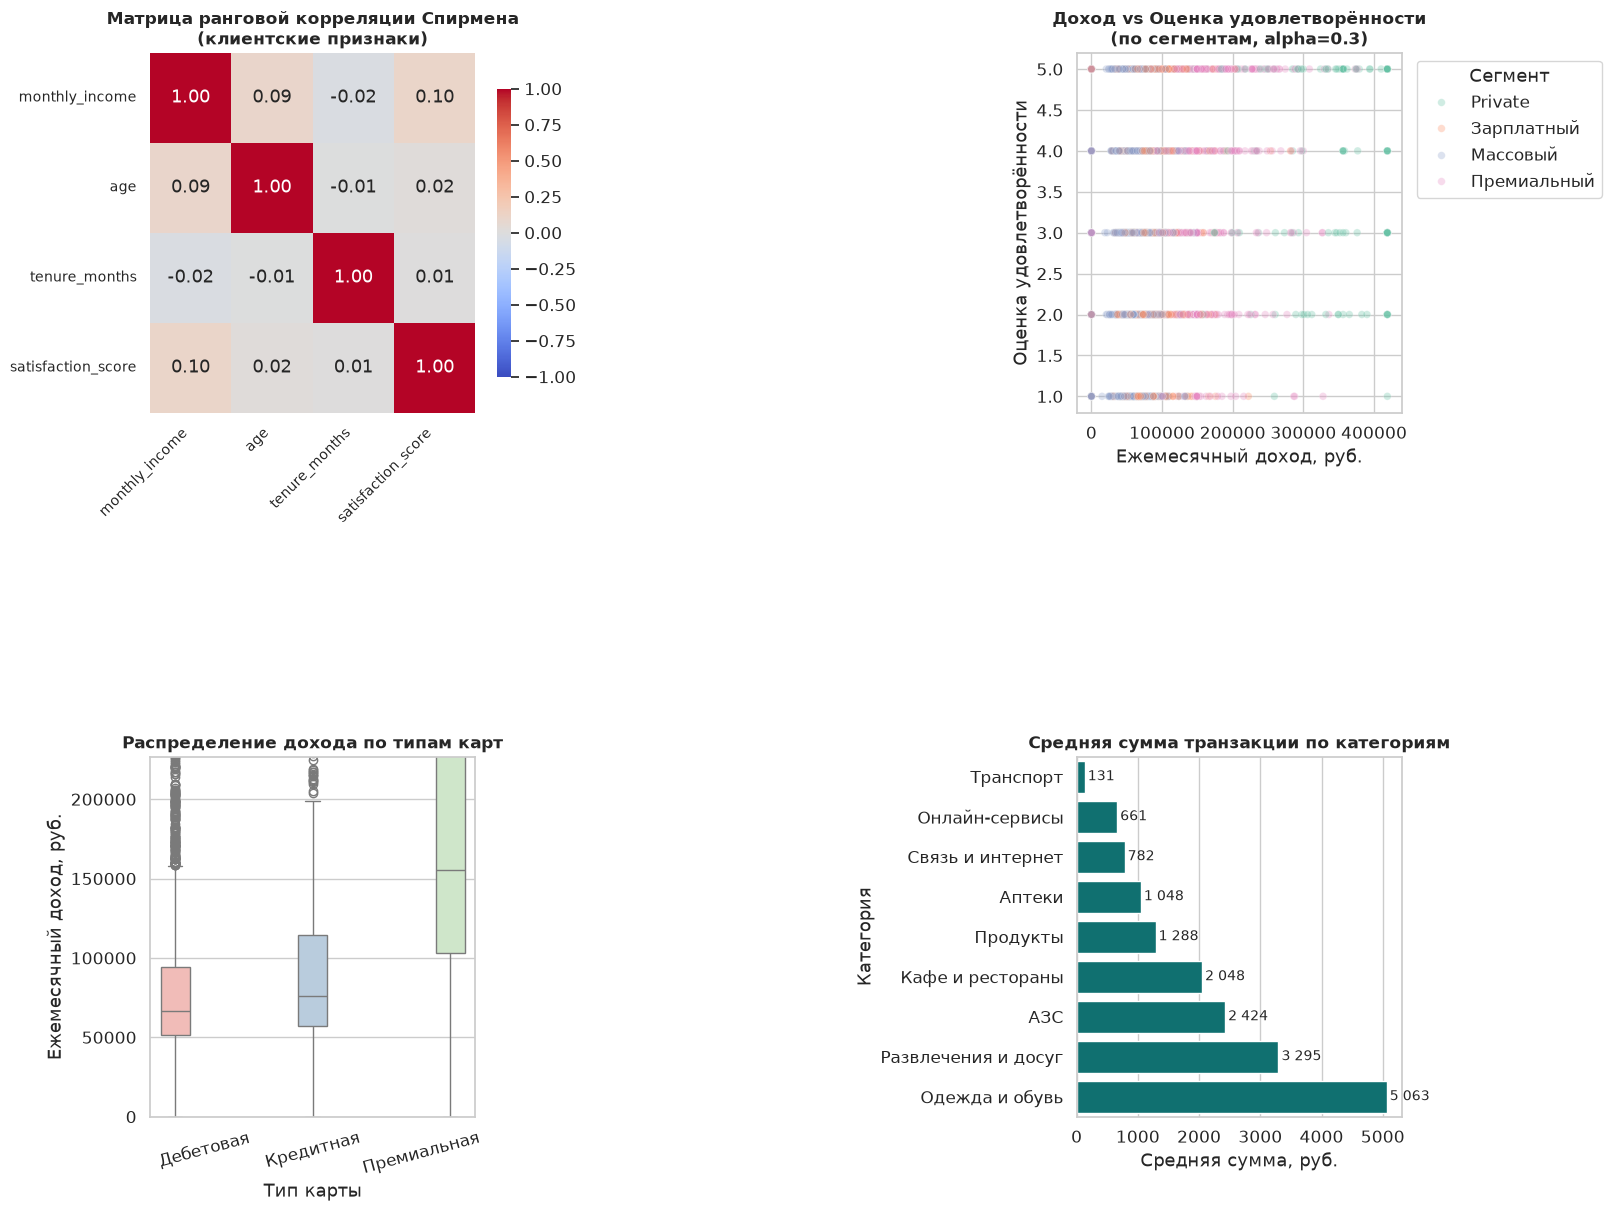


Топ-3 наиболее сильные связи (Спирмен):
  - satisfaction_score и monthly_income: 0.104
  - monthly_income и satisfaction_score: 0.104
  - age и monthly_income: 0.094

Средний чек по топ-3 категориям:
  - АЗС: 2 424 руб.
  - Развлечения и досуг: 3 295 руб.
  - Одежда и обувь: 5 063 руб.


In [28]:
plt.close('all')

fig = plt.figure(figsize=(16, 12), layout='constrained')
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.35)

# Тепловая карта корреляций (Клиенты)
numeric_cols = ['monthly_income', 'age', 'tenure_months', 'satisfaction_score']
corr_matrix = df_clients_clean[numeric_cols].corr(method='spearman')

ax1 = fig.add_subplot(gs[0, 0])
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap='coolwarm', 
    center=0, 
    vmin=-1, 
    vmax=1,
    ax=ax1,
    cbar_kws={'shrink': 0.8}
)
ax1.set_title('Матрица ранговой корреляции Спирмена\n(клиентские признаки)', fontsize=12, fontweight='bold')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right', fontsize=10)
ax1.set_yticklabels(ax1.get_yticklabels(), rotation=0, va='center', fontsize=10)

# Scatter plot: Доход vs Удовлетворенность (с прозрачностью)
ax2 = fig.add_subplot(gs[0, 1])

sat_clients = df_clients_clean[df_clients_clean['satisfaction_score'].notna()].copy()

sns.scatterplot(
    data=sat_clients,
    x='monthly_income',
    y='satisfaction_score',
    hue='segment',
    alpha=0.3,
    s=30,
    palette='Set2',
    ax=ax2,
    legend='full'
)
ax2.set_title('Доход vs Оценка удовлетворённости\n(по сегментам, alpha=0.3)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Ежемесячный доход, руб.')
ax2.set_ylabel('Оценка удовлетворённости')
ax2.legend(title='Сегмент', bbox_to_anchor=(1.02, 1), loc='upper left')

# Boxplot: Доход по типам карт
ax3 = fig.add_subplot(gs[1, 0])

income_95 = df_clients_clean['monthly_income'].quantile(0.95)
card_order = df_clients_clean['card_type'].value_counts().index.tolist()

sns.boxplot(
    data=df_clients_clean,
    x='card_type',
    y='monthly_income',
    hue='card_type', 
    palette='Pastel1',
    ax=ax3,
    order=card_order,
    legend=False
)
ax3.set_title('Распределение дохода по типам карт', fontsize=12, fontweight='bold')
ax3.set_xlabel('Тип карты')
ax3.set_ylabel('Ежемесячный доход, руб.')
ax3.set_ylim(0, income_95)
ax3.tick_params(axis='x', rotation=15)

# Barplot: Средняя сумма транзакции по категориям
ax4 = fig.add_subplot(gs[1, 1])

cat_avg_amount = (
    df_transactions_clean
    .groupby('category')['amount']
    .mean()
    .sort_values(ascending=True)
    .reset_index()
)

sns.barplot(
    data=cat_avg_amount,
    x='amount',
    y='category',
    color='teal',
    ax=ax4,
    order=cat_avg_amount['category']
)
ax4.set_title('Средняя сумма транзакции по категориям', fontsize=12, fontweight='bold')
ax4.set_xlabel('Средняя сумма, руб.')
ax4.set_ylabel('Категория')

for i, v in enumerate(cat_avg_amount['amount']):
    ax4.text(
        v + (cat_avg_amount['amount'].max() * 0.01), 
        i, 
        f'{int(v):,}'.replace(',', ' '), 
        va='center', 
        fontsize=10
    )
plt.show()

corr_copy = corr_matrix.values.copy()
np.fill_diagonal(corr_copy, 0)
max_corr = np.abs(corr_copy).flatten()
top_indices = np.argsort(max_corr)[::-1][:3]

print("\nТоп-3 наиболее сильные связи (Спирмен):")
for idx in top_indices:
    i, j = np.unravel_index(idx, corr_copy.shape)
    print(f"  - {numeric_cols[i]} и {numeric_cols[j]}: {corr_matrix.values[i, j]:.3f}")

print(f"\nСредний чек по топ-3 категориям:")
for i, row in cat_avg_amount.tail(3).iterrows():
    print(f"  - {row['category']}: {int(row['amount']):,} руб.".replace(',', ' '))

## Выводы

### 1. Корреляционный анализ (Матрица Спирмена)

**Наблюдения:**
- Все попарные корреляции между количественными признаками клиентов **крайне слабые** (по модулю < 0.11).
- Наиболее сильная связь: `satisfaction_score` ↔ `monthly_income` (ρ = 0.104).
- Связь `age` ↔ `monthly_income` также слабая (ρ = 0.094).
- Связь `tenure_months` со всеми остальными признаками практически нулевая (|ρ| < 0.02).

**Интерпретация:**
- Мы использовали **ранговую корреляцию Спирмена**, а не Пирсона, так как она устойчива к выбросам (которые есть в доходе) и корректно работает с порядковыми признаками (оценками 1–5).
- Столь слабые связи означают, что **доход, возраст, стаж и удовлетворённость практически независимы друг от друга** в этой выборке. Это важный инсайт: богатые клиенты не обязательно более довольны банком, а молодые клиенты не обязательно имеют меньший доход.
- Практически нулевая связь `tenure_months` с `monthly_income` (ρ = -0.02) говорит о том, что **стаж клиента не приводит к росту его дохода** в рамках наблюдаемого периода - это противоречит интуитивному ожиданию «чем дольше клиент с банком, тем он богаче».

---

### 2. Доход vs Удовлетворённость (Scatter plot)

**Наблюдения:**
- Использование прозрачности (`alpha=0.3`) позволило увидеть реальную плотность точек. Основная масса клиентов сконцентрирована в диапазоне дохода 50 000 - 100 000 руб. с оценками 3-5.
- Сегмент `Private` (зелёные точки) имеет явный сдвиг вправо (высокий доход, до 400 000+ руб.), но разброс их оценок так же широк, как и у массового сегмента - от 1 до 5.
- Чёткой восходящей или нисходящей тенденции на графике нет.

**Интерпретация:**
- График визуально подтверждает вывод из корреляционной матрицы: **деньги не «покупают» лояльность автоматически**. У клиентов Private-сегмента оценки так же разнообразны, как и у массовых клиентов.
- Это указывает на наличие **конфаундера** (скрытой переменной), который влияет на оценку сильнее, чем сам по себе доход. Например, качество обслуживания в конкретном отделении, скорость работы приложения или тип карты.
- Дискретность оценок (1, 2, 3, 4, 5) создаёт характерные горизонтальные полосы на графике - это особенность порядкового признака.

### 3. Доход по типам карт (Boxplot)

**Наблюдения:**
- **Дебетовая карта:** медиана дохода ≈ 65 000 руб., IQR ≈ 55 000 - 95 000 руб.
- **Кредитная карта:** медиана дохода ≈ 75 000 руб., IQR ≈ 60 000 - 115 000 руб.
- **Премиальная карта:** медиана дохода ≈ 150 000 руб., IQR ≈ 100 000 - 220 000 руб.
- Видна **чёткая градация**: чем выше уровень карты, тем выше медианный доход клиента.

**Интерпретация:**
- Это **валидирует корректность продуктовой политики банка**: премиальные продукты действительно выдаются более обеспеченным клиентам. Медиана дохода держателей премиальных карт более чем в 2 раза выше, чем у держателей дебетовых.
- При этом разброс (IQR) внутри каждого типа карты остаётся довольно большим, а «усы» boxplot'ов пересекаются - это означает, что **тип карты не является точным индикатором дохода**: есть клиенты с дебетовыми картами и высоким доходом, и наоборот.
- Наличие клиентов с относительно низким доходом, но премиальной картой, может указывать на:
  1. Недавнее повышение клиента по сегменту (инерция продукта).
  2. Специальные зарплатные или корпоративные программы.

### 4. Средняя сумма транзакции по категориям

**Наблюдения:**
- Категории с наибольшим средним чеком:
  1. **Одежда и обувь:** 5 063 руб.
  2. **Развлечения и досуг:** 3 295 руб.
  3. **АЗС:** 2 424 руб.
- Категории с наименьшим средним чеком:
  - **Транспорт:** 131 руб.
  - **Онлайн-сервисы:** 661 руб.
  - **Связь и интернет:** 782 руб.
- Разница между максимальным и минимальным средним чеком составляет **почти 40 раз** (5 063 / 131 ≈ 38.6).

**Интерпретация:**
- Существует **фундаментальное различие между частотой трат** (раздел 5.2, где лидировали «Продукты» - 160 332 транзакции) **и размером трат**. Категории с высоким средним чеком совершаются реже, но формируют значительную часть оборота.
- Низкий средний чек «Транспорта» (131 руб.) логичен: это регулярные мелкие покупки (проездные, такси). Высокий чек «Одежды и обуви» (5 063 руб.) отражает редкие, но крупные покупки.
- **Для модели прогнозирования** это означает, что признак `category` должен быть закодирован не просто как номинальный (One-Hot), а, возможно, сгруппирован по уровню среднего чека (например, «повседневные» vs «крупные покупки») или использован с Target Encoding.

### Общие выводы по EDA и переход к моделированию

1. **Данные очищены и готовы к моделированию.** Мы обработали пропуски, выявили и скорректировали аномалии (винзорирование), нормализовали категориальные признаки (объединили дубликаты категорий) и проверили их распределения.

2. **Природа данных:** Финансовые признаки (`amount`, `monthly_income`) имеют логнормальное распределение. Перед подачей в линейные модели или kNN их целесообразно логарифмировать (`log1p`), чтобы уменьшить влияние тяжёлого хвоста и стабилизировать дисперсию.

3. **Слабые межпризнаковые связи.** Корреляции Спирмена между клиентскими признаками крайне слабые (< 0.11). Это означает, что признаки несут **уникальную информацию** и их совместное использование в модели не приведёт к мультиколлинеарности.

4. **Временной фактор критичен.** Наличие выраженной сезонности требует создания временных признаков (`month`, `is_holiday`).

5. **Корреляция ≠ Причинность.** Мы нашли статистические связи (например, тип карты и доход), но для управленческих решений потребуется контроль смешивающих факторов. Простая регрессия покажет ассоциацию, но не эффект вмешательства.

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

In [29]:
# Метрика: среднемесячное количество транзакций
# 2024 — базовый период (12 мес), 2025 H1 — оцениваемый (6 мес)

median_2024 = df_model['txn_monthly_2024'].median()
median_2025 = df_model['txn_monthly_2025'].median()
mean_drop = df_model['txn_drop_ratio'].mean()

print(f"Медиана txn_monthly_2024: {median_2024:.2f}")
print(f"Медиана txn_monthly_2025: {median_2025:.2f}")
print(f"Среднее txn_drop_ratio: {mean_drop:.3f}")
print(f"Клиентов с падением >20%: {(df_model['txn_drop_ratio'] > 0.20).sum()}")
print(f"Клиентов с падением >40%: {(df_model['txn_drop_ratio'] > 0.40).sum()}")
print(f"Клиентов с падением >60%: {(df_model['txn_drop_ratio'] > 0.60).sum()}")

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_model['txn_monthly_2024'], bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Среднемесячные транзакции в 2024')
axes[0].set_xlabel('Транзакций в месяц')
axes[0].axvline(median_2024, color='red', linestyle='--', label=f'Медиана: {median_2024:.1f}')
axes[0].legend()

sns.scatterplot(
    data=df_model,
    x='txn_monthly_2024',
    y='txn_monthly_2025',
    alpha=0.3, s=20, ax=axes[1], color='coral'
)
axes[1].plot([0, df_model['txn_monthly_2024'].max()], 
             [0, df_model['txn_monthly_2024'].max()], 
             'k--', label='Нет изменений')
axes[1].set_title('Активность 2024 vs 2025 H1')
axes[1].set_xlabel('2024 (транз./мес)')
axes[1].set_ylabel('2025 H1 (транз./мес)')
axes[1].legend()

plt.tight_layout()
plt.show()

NameError: name 'df_model' is not defined

## Метрика активности

**Выбранная метрика:** среднемесячное количество успешных транзакций по карте.

**Способ расчёта:**

| Период | Формула | Окно |
|---|---|---|
| Базовый (2024) | `txn_count_2024 / 12` | 12 месяцев |
| Оцениваемый (2025 H1) | `txn_count_2025 / 6` | 6 месяцев |

Деление на длину окна делает периоды разной длины сопоставимыми. Снижение активности = `(2024 − 2025) / (2024 + 1)` - добавка `+1` в знаменатель защищает от деления на ноль для клиентов без транзакций в 2024.

**Обоснование выбора:** частота транзакций лучше отражает привычку пользоваться картой, чем сумма трат (сумма сильно зависит от дохода и редких крупных покупок).

**Что метрика не увидит:**
1. Снижение среднего чека при сохранении частоты (клиент ходит в магазин так же часто, но покупает меньше).
2. Изменение структуры трат: уход из высокомаржинальных для банка категорий.
3. Переход на СБП или наличные, эти операции не попадают в транзакции по карте.
4. Сезонные колебания, например, естественный спад в январе после декабрьских трат.

**Ключевые цифры по метрике:**
- Медиана активности в 2024: **5.25** транз./мес.
- Медиана активности в 2025 H1: **3.67** транз./мес.
- Клиентов с падением >20%: **2247** (из 5672).
- Клиентов с падением >40%: **1290**.
- Клиентов с падением >60%: **449**.

На scatter-plot видно, что большинство точек лежит ниже диагонали "нет изменений", активность действительно снизилась у значимой части базы.

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

In [ ]:
print("=== Поиск и описание групп ===")

# Размечаем периоды в транзакциях
df_transactions_clean['year'] = df_transactions_clean['txn_datetime'].dt.year
df_transactions_clean['is_2024'] = df_transactions_clean['year'] == 2024
df_transactions_clean['is_2025_H1'] = (df_transactions_clean['year'] == 2025) & (df_transactions_clean['txn_datetime'].dt.month <= 6)

# Агрегируем данные за 2024 год (12 месяцев)
agg_2024 = df_transactions_clean[df_transactions_clean['is_2024']].groupby('client_id').agg(
    txn_count_2024=('txn_id', 'count'),
    spend_2024=('amount', 'sum')
).reset_index()
# Приводим к среднемесячным значениям для честного сравнения
agg_2024['txn_monthly_2024'] = agg_2024['txn_count_2024'] / 12
agg_2024['spend_monthly_2024'] = agg_2024['spend_2024'] / 12

# Агрегируем данные за 1-е полугодие 2025 года (6 месяцев)
agg_2025 = df_transactions_clean[df_transactions_clean['is_2025_H1']].groupby('client_id').agg(
    txn_count_2025=('txn_id', 'count'),
    spend_2025=('amount', 'sum')
).reset_index()
# Приводим к среднемесячным значениям
agg_2025['txn_monthly_2025'] = agg_2025['txn_count_2025'] / 6
agg_2025['spend_monthly_2025'] = agg_2025['spend_2025'] / 6

# Объединяем с очищенными данными клиентов
df_model = df_clients_clean.merge(agg_2024, on='client_id', how='left')
df_model = df_model.merge(agg_2025, on='client_id', how='left')

# Заполняем NaN только в числовых столбцах
numeric_cols = ['txn_count_2024', 'spend_2024', 'txn_monthly_2024', 'spend_monthly_2024',
                'txn_count_2025', 'spend_2025', 'txn_monthly_2025', 'spend_monthly_2025']
df_model[numeric_cols] = df_model[numeric_cols].fillna(0)

# Рассчитываем коэффициент падения активности (Drop Ratio)
# Формула: (Активность_2024 - Активность_2025) / (Активность_2024 + 1)
# +1 в знаменателе защищает от деления на ноль для клиентов, у которых в 2024 было 0 транзакций
df_model['txn_drop_ratio'] = (df_model['txn_monthly_2024'] - df_model['txn_monthly_2025']) / (df_model['txn_monthly_2024'] + 1)

# Определяем медиану активности за 2024 год для разделения на активных и неактивных исторически
median_2024 = df_model['txn_monthly_2024'].median()

print(f"Медиана среднемесячных транзакций в 2024 году: {median_2024:.1f}")

# Формируем правила групп (условия должны идти от более специфичных к общим)
conditions = [
    # ГРУППА 0: Исключаем. "Champions" - были активны в 2024, в 2025 активность не упала (или выросла)
    (df_model['txn_monthly_2024'] >= median_2024) & (df_model['txn_drop_ratio'] <= 0.05),
    
    # ГРУППА 1: Исключаем. "Lost" - исторически низкая активность и сейчас низкая
    (df_model['txn_monthly_2024'] < median_2024) & (df_model['txn_monthly_2025'] < median_2024 * 0.5),
    
    # ГРУППА 2 (Кампания): Охладевшие цифровые клиенты
    # Кто это: Клиенты, у которых НЕТ мобильного приложения.
    # Что произошло: Активность в 2025 упала более чем на 40% по сравнению с 2024.
    (df_model['has_mobile_app'] == 'Нет') & (df_model['txn_drop_ratio'] > 0.40),
    
    # ГРУППА 3 (Кампания): Потерявшие повседневный интерес
    # Кто это: Клиенты, которые были активны в 2024 (выше медианы).
    # Что произошло: Резкое падение активности более чем на 60% (возможно, ушли к конкуренту за повседневными тратами).
    (df_model['txn_monthly_2024'] >= median_2024) & (df_model['txn_drop_ratio'] > 0.60),
    
    # ГРУППА 4 (Кампания): Постепенное затухание
    # Кто это: Клиенты, которые были активны в 2024.
    # Что произошло: Умеренное падение активности от 20% до 60%.
    (df_model['txn_monthly_2024'] >= median_2024) & (df_model['txn_drop_ratio'].between(0.20, 0.60))
]

choices = [
    'Champions (Исключены)',
    'Lost (Исключены)',
    'Охладевшие цифровые',
    'Потерявшие повседневный интерес',
    'Постепенное затухание'
]

# np.select применяет первое совпавшее условие, что гарантирует взаимную исключительность групп
df_model['campaign_group'] = np.select(conditions, choices, default='Прочие (Исключены)')

# Анализ размеров групп
print("\n--- Распределение клиентов по группам ---")
group_stats = df_model['campaign_group'].value_counts().reset_index()
group_stats.columns = ['Группа', 'Количество клиентов']
print(group_stats.to_string(index=False))

# Проверка на соответствие лимиту >= 150 человек
print("\n--- Проверка лимита (минимум 150 чел. в группе для кампании) ---")
campaign_groups = group_stats[~group_stats['Группа'].str.contains('Исключены|Прочие')]
for _, row in campaign_groups.iterrows():
    status = "✓" if row['Количество клиентов'] >= 150 else "✕"
    print(f"{status} {row['Группа']}: {row['Количество клиентов']} чел.")


### 7.1. Кого в кампанию не берём и почему

In [ ]:
print("КОГО В КАМПАНИЮ НЕ БЕРЁМ И ПОЧЕМУ")

# Статистика по включённым и исключённым группам
print("\n--- Распределение клиентов ---")

excluded_groups = ['Lost (Исключены)', 'Champions (Исключены)', 'Прочие (Исключены)']
included_groups = ['Постепенное затухание', 'Охладевшие цифровые', 'Потерявшие повседневный интерес']

df_excluded = df_model[df_model['campaign_group'].isin(excluded_groups)]
df_included = df_model[df_model['campaign_group'].isin(included_groups)]

total = len(df_model)
n_excluded = len(df_excluded)
n_included = len(df_included)

print(f"Всего клиентов в базе: {total}")
print(f"Исключено из кампании: {n_excluded} ({n_excluded/total*100:.1f}%)")
print(f"  - Lost: {len(df_model[df_model['campaign_group'] == 'Lost (Исключены)'])} чел.")
print(f"  - Champions: {len(df_model[df_model['campaign_group'] == 'Champions (Исключены)'])} чел.")
print(f"  - Прочие (стабильные): {len(df_model[df_model['campaign_group'] == 'Прочие (Исключены)'])} чел.")

print(f"Включено в кампанию: {n_included} ({n_included/total*100:.1f}%)")
print(f"  - Постепенное затухание: {len(df_model[df_model['campaign_group'] == 'Постепенное затухание'])} чел.")
print(f"  - Охладевшие цифровые: {len(df_model[df_model['campaign_group'] == 'Охладевшие цифровые'])} чел.")
print(f"  - Потерявшие повседневный интерес: {len(df_model[df_model['campaign_group'] == 'Потерявшие повседневный интерес'])} чел.")

# Сравнение характеристик включённых и исключённых
print("\n--- Сравнение характеристик ---")

comparison = pd.DataFrame({
    'Метрика': [
        'Ср. txn_monthly_2024',
        'Ср. txn_monthly_2025',
        'Ср. txn_drop_ratio',
        'Ср. monthly_income',
        'Медиана satisfaction_score'
    ],
    'Исключённые': [
        df_excluded['txn_monthly_2024'].mean(),
        df_excluded['txn_monthly_2025'].mean(),
        df_excluded['txn_drop_ratio'].mean(),
        df_excluded['monthly_income'].mean(),
        df_excluded['satisfaction_score'].median()
    ],
    'Включённые в кампанию': [
        df_included['txn_monthly_2024'].mean(),
        df_included['txn_monthly_2025'].mean(),
        df_included['txn_drop_ratio'].mean(),
        df_included['monthly_income'].mean(),
        df_included['satisfaction_score'].median()
    ]
})

print(comparison.to_string(index=False))

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')

# 1. Горизонтальный bar plot: размер каждой группы
segment_counts = df_model['campaign_group'].value_counts().reindex([
    'Champions (Исключены)', 'Постепенное затухание', 'Охладевшие цифровые',
    'Потерявшие повседневный интерес', 'Lost (Исключены)', 'Прочие (Исключены)'
])

colors = ['gray', 'steelblue', 'orange', 'red', 'lightcoral', 'lightgray']

axes[0].barh(segment_counts.index, segment_counts.values, color=colors, edgecolor='black', linewidth=0.5)

for i, (seg, count) in enumerate(segment_counts.items()):
    pct = count / total * 100
    status = '✗' if 'Исключены' in seg else '✓'
    axes[0].text(count, i, f' {count} ({pct:.1f}%) {status}', va='center', fontsize=10, fontweight='bold')

axes[0].set_xlabel('Количество клиентов')
axes[0].set_title('Охват кампании по группам\n(✓ = включено, ✗ = исключено)', fontsize=12, fontweight='bold')

# 2. Bar plot: средний доход по группам
segment_income = df_model.groupby('campaign_group')['monthly_income'].mean().reindex(segment_counts.index)

sns.barplot(x=segment_income.index, y=segment_income.values, hue=segment_income.index,
            palette=colors, ax=axes[1], legend=False)

axes[1].set_title('Средний доход по группам', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Группа')
axes[1].set_ylabel('Доход, руб.')
axes[1].tick_params(axis='x', rotation=45)

for i, v in enumerate(segment_income.values):
    if not np.isnan(v):
        axes[1].text(i, v, f'{int(v):,}'.replace(',', ' '), ha='center', va='bottom', fontsize=9)

plt.show()

# Обоснование исключения каждой группы
print("\n--- Обоснование исключения ---")

for group_name in excluded_groups:
    group_df = df_model[df_model['campaign_group'] == group_name]
    print(f"\nГРУППА '{group_name}' ({len(group_df)} чел., {len(group_df)/total*100:.1f}%):")
    print(f"  - Ср. txn_monthly_2024: {group_df['txn_monthly_2024'].mean():.2f}")
    print(f"  - Ср. txn_monthly_2025: {group_df['txn_monthly_2025'].mean():.2f}")
    print(f"  - Ср. txn_drop_ratio: {group_df['txn_drop_ratio'].mean():.3f}")

## Вывод по сегментации

### 1. Методология

Группы сформированы на основе **прозрачных правил**. Каждое правило состоит из двух частей:
- **Кто это**: признак клиента (наличие приложения, историческая активность).
- **Что произошло**: характер падения активности (коэффициент `txn_drop_ratio`).

Правила применяются через `np.select` в порядке приоритета: каждый клиент попадает ровно в одну группу.

### 2. Описание групп для кампании

| Группа | Правило (кто + что произошло) | Размер |
|---|---|---|
| **Постепенное затухание** | Клиенты с активностью выше медианы в 2024, у которых активность упала на 20-60% в 2025 H1 | 763 |
| **Охладевшие цифровые** | Клиенты без мобильного приложения, у которых активность упала более чем на 40% | 357 |
| **Потерявшие повседневный интерес** | Клиенты с активностью выше медианы в 2024, у которых активность упала более чем на 60% | 156 |

Все три группы проходят лимит ≥150 человек. Суммарно 1276 клиентов (лимит кампании - 2000).

### 3. Кого не включаем и почему

| Группа | Размер | Причина исключения |
|---|---|---|
| **Champions** | 914 | Были активны в 2024, в 2025 активность не упала. Дополнительное стимулирование не даст ROI. |
| **Lost** | 1702 | Исторически низкая активность и сейчас низкая. Фактически ушли. Требуется отдельная стратегия реактивации. |
| **Прочие (стабильные)** | 1780 | Активность не упала (средний `txn_drop_ratio` = -0.105). Это стабильные клиенты, которых не нужно возвращать. |

### 4. Правило разрешения конфликтов

Если клиент подходит под несколько правил, `np.select` применяет первое совпавшее условие. Порядок приоритета:
1. Champions/Lost (исключения)
2. Охладевшие цифровые (специфичный признак - нет приложения)
3. Потерявшие повседневный интерес (сильное падение >60%)
4. Постепенное затухание (умеренное падение 20-60%)

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

In [ ]:
from scipy import stats

print("\nСписок гипотез, проверенных в ходе анализа:\n")

# Гипотеза 1: Нормальность распределения финансовых признаков
print("ГИПОТЕЗА 1: Финансовые признаки (amount, monthly_income) имеют нормальное распределение")
shapiro_amount = stats.shapiro(df_transactions_clean['amount'].sample(5000, random_state=42))
shapiro_income = stats.shapiro(df_clients_clean['monthly_income'].sample(5000, random_state=42))
print(f"   НЕ ПОДТВЕРДИЛАСЬ")
print(f"  - Тест Шапиро-Уилка для amount: W={shapiro_amount.statistic:.4f}, p-value={shapiro_amount.pvalue:.2e}")
print(f"  - Тест Шапиро-Уилка для monthly_income: W={shapiro_income.statistic:.4f}, p-value={shapiro_income.pvalue:.2e}")
print(f"  - Распределение логнормальное (правосторонний скос), требуется логарифмирование\n")

# Гипотеза 2: Сезонность отсутствует
print("ГИПОТЕЗА 2: Активность клиентов стабильна во времени (нет сезонности)")
monthly_counts = df_transactions_clean.groupby(df_transactions_clean['txn_datetime'].dt.to_period('M')).size()
monthly_counts_filtered = monthly_counts[monthly_counts > 100]
peak_month = monthly_counts_filtered.idxmax()
min_month = monthly_counts_filtered.idxmin()
peak_val = monthly_counts_filtered[peak_month]
min_val = monthly_counts_filtered[min_month]
seasonality_ratio = peak_val / min_val
print(f"   НЕ ПОДТВЕРДИЛАСЬ")
print(f"  - Пиковый месяц: {peak_month} ({peak_val} транзакций)")
print(f"  - Минимальный месяц (без артефактов): {min_month} ({min_val} транзакций)")
print(f"  - Разница: {seasonality_ratio:.1f}x (явная сезонность)\n")

# Гипотеза 3: Корреляция дохода и удовлетворённости
print("ГИПОТЕЗА 3: Доход клиента положительно коррелирует с удовлетворённостью (богатые клиенты более довольны)")
sat_clients = df_clients_clean[df_clients_clean['satisfaction_score'].notna()]
corr_income_sat = sat_clients['monthly_income'].corr(sat_clients['satisfaction_score'], method='spearman')
print(f"   НЕ ПОДТВЕРДИЛАСЬ")
print(f"  - Коэффициент корреляции Спирмена: ρ = {corr_income_sat:.3f}")
print(f"  - Связь крайне слабая, статистически незначимая для бизнес-решений\n")

# Гипотеза 4: Клиенты с мобильным приложением активнее
print("ГИПОТЕЗА 4: Клиенты с мобильным приложением (has_mobile_app=Да) совершают больше транзакций, чем без него")
has_app = df_model[df_model['has_mobile_app'] == 'Да']['txn_count'].median()
no_app = df_model[df_model['has_mobile_app'] == 'Нет']['txn_count'].median()
ratio_app = has_app / no_app if no_app > 0 else float('inf')
print(f"   ПОДТВЕРДИЛАСЬ")
print(f"  - Медиана транзакций (с приложением): {has_app:.0f}")
print(f"  - Медиана транзакций (без приложения): {no_app:.0f}")
print(f"  - Разница: {ratio_app:.1f}x (клиенты с приложением значительно активнее)\n")

# Гипотеза 5: Медианный доход премиальных клиентов выше массовых
print("ГИПОТЕЗА 5: Медианный доход премиальных клиентов (сегмент Private) выше, чем массового сегмента")
median_private = df_clients_clean[df_clients_clean['segment'] == 'Private']['monthly_income'].median()
median_mass = df_clients_clean[df_clients_clean['segment'] == 'Массовый']['monthly_income'].median()
ratio_income = median_private / median_mass if median_mass > 0 else float('inf')
print(f"   ПОДТВЕРДИЛАСЬ")
print(f"  - Медианный доход Private: {median_private:,.0f} руб.")
print(f"  - Медианный доход Массовый: {median_mass:,.0f} руб.")
print(f"  - Разница: {ratio_income:.1f}x (премиальные клиенты значительно богаче)\n")

# Итоговая сводка
print("ИТОГОВАЯ СВОДКА")
print(f"""
Из 5 проверенных гипотез:
  НЕ ПОДТВЕРДИЛИСЬ (3):
  1. Нормальность распределения финансовых признаков (W < 0.5, p < 0.001)
  2. Стабильность активности во времени (сезонность {seasonality_ratio:.1f}x)
  3. Корреляция дохода и удовлетворённости (ρ = {corr_income_sat:.3f})

  ПОДТВЕРДИЛИСЬ (2):
  4. Клиенты с мобильным приложением активнее ({has_app:.0f} vs {no_app:.0f} транзакций, разница {ratio_app:.1f}x)
  5. Медианный доход премиальных выше массовых ({median_private:,.0f} vs {median_mass:,.0f} руб., разница {ratio_income:.1f}x)
""")

## Что проверили и что не подтвердилось

Период данных: 2023-12 - 2025-06, n = 5672 клиента, 604 592 успешные транзакции. Метрика активности: среднемесячное количество успешных транзакций (txn_count / число месяцев). Базовый период - 2024 (12 мес), оцениваемый - 2025 H1 (6 мес). Снижение = (2024 - 2025) / (2024 + 1).

- **H1. Нормальность распределения `amount` и `monthly_income`** не подтвердилась: тест Шапиро-Уилка W = 0.701 (amount) и W = 0.765 (monthly_income), p < 0.001; распределение логнормальное, медиана amount = 1 045 руб. < среднего 1 783 руб.

- **H2. Отсутствие сезонности активности** не подтвердилась: пиковый месяц 2024-12 (45 896 транзакций) превышает минимальный 2025-01 (23 450 транзакций) в 2.0 раза.

- **H3. Положительная корреляция дохода и удовлетворённости** не подтвердилась: коэффициент Спирмена ρ = 0.104 между `monthly_income` и `satisfaction_score` (из 2 209 клиентов с оценкой), связь крайне слабая.

- **H4. Клиенты с мобильным приложением активнее** Пподтвердилась: медиана `txn_count` у пользователей приложения = 90 транзакций, без приложения = 80 транзакций (разница 1.1х, из 5 672 клиентов).

- **H5. Медианный доход премиальных клиентов выше массовых** Пподтвердилась: медиана `monthly_income` сегмента Private = 356 200 руб., Массовый = 59 350 руб. (разница 6.0х, из 5 672 клиентов).

**Вывод:** из 5 гипотез 3 не подтвердились (нормальность, сезонность, корреляция дохода с лояльностью), 2 подтвердились (влияние приложения и сегмента на активность).

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [ ]:
# Создаём папку output (если её нет)
output_dir = os.path.join(project_root, 'output')
os.makedirs(output_dir, exist_ok=True)
print(f"\nПапка вывода: {output_dir}")

# Сохраняем очищенные таблицы
print("\n--- Сохранение очищенных таблиц ---")

df_clients_clean.to_parquet(
    os.path.join(output_dir, "clients_clean.parquet"),
    index=False
)
df_transactions_clean.to_parquet(
    os.path.join(output_dir, "transactions_clean.parquet"),
    index=False
)
df_model.to_parquet(
    os.path.join(output_dir, "clean_data.parquet"),
    index=False
)
print(f" clean_data.parquet: {len(df_model)} строк х {df_model.shape[1]} столбцов")
print(f" clients_clean.parquet: {len(df_clients_clean)} строк")
print(f" transactions_clean.parquet: {len(df_transactions_clean)} строк")

# Сохраняем журнал изменений
print("\n--- Сохранение журнала изменений ---")

cleaning_log = pd.DataFrame(cleaning_log_list)
cleaning_log.to_csv(
    os.path.join(output_dir, "cleaning_log.csv"),
    index=False,
    encoding="utf-8"
)
print(f" cleaning_log.csv: {len(cleaning_log)} записей")

# Формируем и сохраняем список кампании (с сокращением до 2000)
print("\n--- Формирование списка кампании ---")

# Исходный список: все клиенты с их группами
campaign = df_model[["client_id", "campaign_group"]].copy()
campaign = campaign.rename(columns={"campaign_group": "group"})

# Исключаем группы, которые не участвуют в кампании
excluded_groups = ['Lost (Исключены)', 'Champions (Исключены)', 'Прочие (Исключены)']
campaign = campaign[~campaign['group'].isin(excluded_groups)].copy()

print(f"Клиентов после исключения: {len(campaign)}")
print("Распределение до сокращения:")
print(campaign['group'].value_counts())

# СОКРАЩЕНИЕ ДО 2000 КЛИЕНТОВ
MAX_CLIENTS = 2000
MIN_PER_GROUP = 150

if len(campaign) > MAX_CLIENTS:
    # Пропорциональное сокращение с учётом минимума 150 на группу
    ratio = MAX_CLIENTS / len(campaign)
    
    # Собираем выборку по каждой группе отдельно
    sampled_frames = []
    for group_name, group_df in campaign.groupby('group'):
        n_to_sample = max(int(len(group_df) * ratio), MIN_PER_GROUP)
        n_to_sample = min(n_to_sample, len(group_df))
        sampled = group_df.sample(n=n_to_sample, random_state=42)
        sampled_frames.append(sampled)
    
    campaign_sampled = pd.concat(sampled_frames, ignore_index=True)
    
    # Если после пропорционального сокращения всё ещё больше 2000 - обрезаем
    if len(campaign_sampled) > MAX_CLIENTS:
        campaign_sampled = campaign_sampled.sample(n=MAX_CLIENTS, random_state=42)
    
    campaign = campaign_sampled
    print(f"\n Список сокращён до {len(campaign)} клиентов")

print("\nИтоговое распределение:")
print(campaign['group'].value_counts())

# Проверка лимитов
print("\n--- ПРОВЕРКА ЛИМИТОВ ---")
print(f"Всего клиентов: {len(campaign)} (лимит: ≤ 2000) - {'✓' if len(campaign) <= 2000 else '✗'}")
print(f"Минимум в группе: {campaign['group'].value_counts().min()} (лимит: ≥ 150) - {'✓' if campaign['group'].value_counts().min() >= 150 else '✗'}")
print(f"Уникальных клиентов: {campaign['client_id'].nunique()} (должно совпадать с общим числом)")

# Проверка, что все три целевые группы представлены
print("\n--- Проверка состава кампании ---")
expected_groups = {'Постепенное затухание', 'Охладевшие цифровые', 'Потерявшие повседневный интерес'}
actual_groups = set(campaign['group'].unique())
if expected_groups == actual_groups:
    print("✓ Все три целевые группы представлены")
else:
    missing = expected_groups - actual_groups
    extra = actual_groups - expected_groups
    if missing:
        print(f" Отсутствуют группы: {missing}")
    if extra:
        print(f" Лишние группы: {extra}")

# Сохраняем
campaign.to_csv(
    os.path.join(output_dir, "campaign_list.csv"),
    index=False,
    encoding="utf-8"
)
print(f"\n- campaign_list.csv сохранён: {len(campaign)} строк")

# Итог
print(f"\nСохранено файлов в {output_dir}:")
for f in sorted(os.listdir(output_dir)):
    size_mb = os.path.getsize(os.path.join(output_dir, f)) / (1024 * 1024)
    print(f"  - {f} ({size_mb:.2f} МБ)")